In [10]:
from pathlib import Path

DATASET_DIR = Path(r"D:\archive")

extensions = {".tif", ".tiff", ".jpg", ".jpeg", ".png", ".irg"}

files = [
    p for p in DATASET_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

print("All image/data files by extension:")
for ext in sorted(extensions):
    count = sum(p.suffix.lower() == ext for p in files)
    print(f"{ext}: {count}")

geo_tiffs = [
    p for p in DATASET_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".tif", ".tiff"}
    and "geo_thermal_tiff_celsius" in str(p).lower()
]

print("\nGeoreferenced thermal TIFFs:", len(geo_tiffs))

All image/data files by extension:
.irg: 818
.jpeg: 1
.jpg: 2172
.png: 794
.tif: 8
.tiff: 1613

Georeferenced thermal TIFFs: 794


In [14]:

geo_images = sorted(
    p for p in DATASET_PATH.rglob("*")
    if p.is_file()
    and p.suffix.lower() in [".tif", ".tiff"]
    and "geo_thermal_tiff_celsius" in str(p).lower()
)

print("Georeferenced thermal TIFFs:", len(geo_images))

for path in geo_images[:10]:
    print(path)


Georeferenced thermal TIFFs: 794
D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0529_ref_geo.TIFF
D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0530_ref_geo.TIFF
D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0531_ref_geo.TIFF
D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0532_ref_geo.TIFF
D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0533_ref_geo.TIFF
D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0534_ref_geo.TIFF
D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0535_ref_geo.TIFF
D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0536_ref_geo.TIFF
D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0537_ref_geo.TIFF
D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0538_ref_geo.TIFF


In [15]:

import sys
print(sys.executable)


D:\jupyter\python.exe


In [13]:

import sys
!{sys.executable} -m pip install rasterio


In [16]:

import rasterio
print("Rasterio version:", rasterio.__version__)
print("Rasterio installed successfully!")


Rasterio version: 1.5.2
Rasterio installed successfully!


In [17]:

from pathlib import Path
import rasterio
import numpy as np

# Dataset folder
DATASET_PATH = Path(r"D:\archive")

# Find georeferenced thermal TIFF images
geo_images = sorted(
    p for p in DATASET_PATH.rglob("*")
    if p.is_file()
    and p.suffix.lower() in [".tif", ".tiff"]
    and "geo_thermal_tiff_celsius" in str(p).lower()
)

print("Total georeferenced thermal images:", len(geo_images))
print("First image:", geo_images[0] if geo_images else "No images found")


Total georeferenced thermal images: 794
First image: D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0529_ref_geo.TIFF


In [18]:

for path in geo_images[:5]:
    with rasterio.open(path) as src:
        image = src.read(1)

        print("\nImage:", path.name)
        print("Shape:", image.shape)
        print("Data type:", image.dtype)
        print("CRS:", src.crs)
        print("Valid pixels:", np.isfinite(image).sum())
        print("Minimum value:", np.nanmin(image))
        print("Maximum value:", np.nanmax(image))



Image: IRX_0529_ref_geo.TIFF
Shape: (531, 654)
Data type: float32
CRS: EPSG:26916
Valid pixels: 347274
Minimum value: 0.0
Maximum value: 197.0

Image: IRX_0530_ref_geo.TIFF
Shape: (531, 654)
Data type: float32
CRS: EPSG:26916
Valid pixels: 347274
Minimum value: 0.0
Maximum value: 197.0

Image: IRX_0531_ref_geo.TIFF
Shape: (531, 654)
Data type: float32
CRS: EPSG:26916
Valid pixels: 347274
Minimum value: 0.0
Maximum value: 197.0

Image: IRX_0532_ref_geo.TIFF
Shape: (531, 654)
Data type: float32
CRS: EPSG:26916
Valid pixels: 347274
Minimum value: 0.0
Maximum value: 197.0

Image: IRX_0533_ref_geo.TIFF
Shape: (531, 654)
Data type: float32
CRS: EPSG:26916
Valid pixels: 347274
Minimum value: 0.0
Maximum value: 197.0


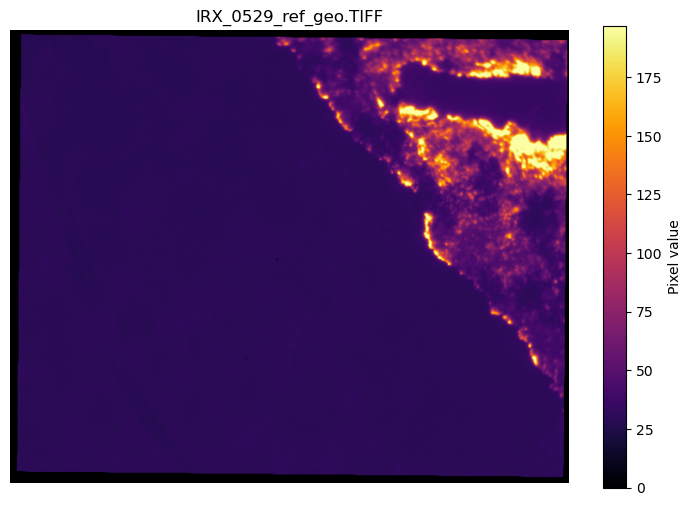

In [19]:

import matplotlib.pyplot as plt
import numpy as np
import rasterio

sample_path = geo_images[0]

with rasterio.open(sample_path) as src:
    thermal_image = src.read(1).astype(np.float32)

thermal_image[~np.isfinite(thermal_image)] = np.nan

plt.figure(figsize=(9, 6))
plt.imshow(thermal_image, cmap="inferno")
plt.colorbar(label="Pixel value")
plt.title(sample_path.name)
plt.axis("off")
plt.show()


In [20]:

from collections import Counter

folder_counts = Counter(
    str(path.parent.relative_to(DATASET_PATH))
    for path in geo_images
)

for folder, count in sorted(folder_counts.items()):
    print(f"{folder}: {count} images")


Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius: 296 images
Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part1: 322 images
Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part2: 176 images


In [21]:

for path in geo_images[:20]:
    print(path.name)


IRX_0529_ref_geo.TIFF
IRX_0530_ref_geo.TIFF
IRX_0531_ref_geo.TIFF
IRX_0532_ref_geo.TIFF
IRX_0533_ref_geo.TIFF
IRX_0534_ref_geo.TIFF
IRX_0535_ref_geo.TIFF
IRX_0536_ref_geo.TIFF
IRX_0537_ref_geo.TIFF
IRX_0538_ref_geo.TIFF
IRX_0539_ref_geo.TIFF
IRX_0540_ref_geo.TIFF
IRX_0541_ref_geo.TIFF
IRX_0542_ref_geo.TIFF
IRX_0543_ref_geo.TIFF
IRX_0544_ref_geo.TIFF
IRX_0545_ref_geo.TIFF
IRX_0546_ref_geo.TIFF
IRX_0547_ref_geo.TIFF
IRX_0548_ref_geo.TIFF


In [22]:

from pathlib import Path
import re

folders = {}

for path in geo_images:
    folders.setdefault(path.parent, []).append(path)

for folder, paths in sorted(folders.items(), key=lambda x: str(x[0])):
    paths = sorted(paths)
    numbers = []

    for path in paths:
        match = re.search(r"IRX_(\d+)_ref_geo", path.name, re.IGNORECASE)
        if match:
            numbers.append(int(match.group(1)))

    print("\nFolder:", folder)
    print("Images:", len(paths))

    if numbers:
        print("First frame number:", numbers[0])
        print("Last frame number:", numbers[-1])
        gaps = [
            (a, b) for a, b in zip(numbers, numbers[1:])
            if b != a + 1
        ]
        print("Numbering gaps:", len(gaps))
        print("First gaps:", gaps[:10])



Folder: D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius
Images: 296
First frame number: 529
Last frame number: 824
Numbering gaps: 0
First gaps: []

Folder: D:\archive\Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part1
Images: 322
First frame number: 826
Last frame number: 1147
Numbering gaps: 0
First gaps: []

Folder: D:\archive\Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part2
Images: 176
First frame number: 1171
Last frame number: 1346
Numbering gaps: 0
First gaps: []


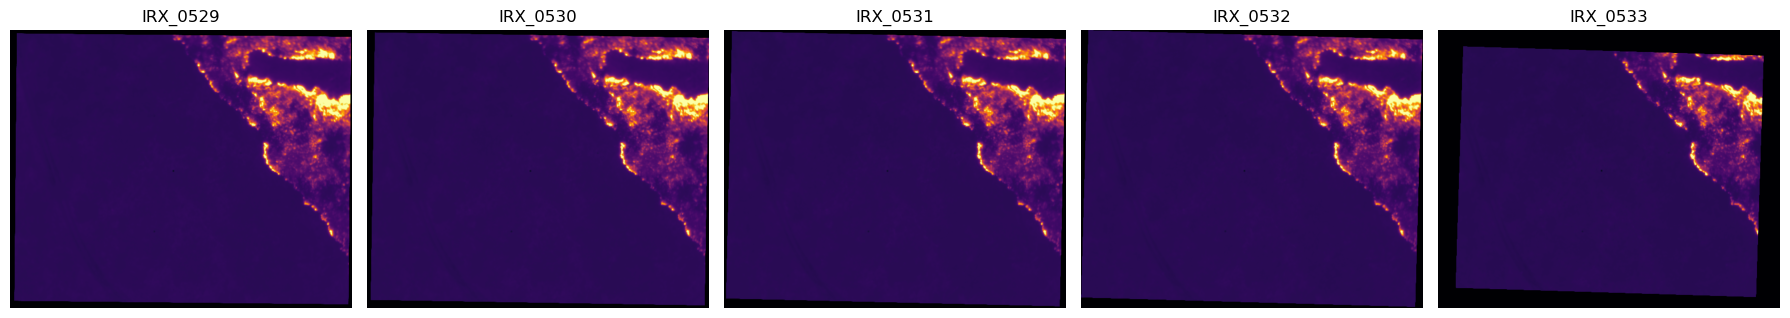

In [23]:

import matplotlib.pyplot as plt
import rasterio
import numpy as np

plot1_paths = sorted(
    p for p in geo_images
    if "plot 1" in str(p).lower()
    and "duringburn" in str(p).lower()
)

fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for ax, path in zip(axes, plot1_paths[:5]):
    with rasterio.open(path) as src:
        image = src.read(1).astype(np.float32)

    image[~np.isfinite(image)] = np.nan
    ax.imshow(image, cmap="inferno", vmin=0, vmax=197)
    ax.set_title(path.name.replace("_ref_geo.TIFF", ""))
    ax.axis("off")

plt.tight_layout()
plt.show()


In [24]:

from pathlib import Path

DATASET_PATH = Path(r"D:\archive")

checkpoints = list(DATASET_PATH.rglob("unet_fire_segmentation_final.pth"))

print("U-Net checkpoints found:", len(checkpoints))

for checkpoint in checkpoints:
    print(checkpoint)


U-Net checkpoints found: 0


In [25]:

from pathlib import Path

locations = [
    Path.home() / "Desktop",
    Path.home() / "OneDrive" / "Desktop",
    Path(r"C:\Users\shash\OneDrive\Desktop"),
    Path(r"D:\archive")
]

for location in locations:
    print("\nChecking:", location, "Exists:", location.exists())

    if location.exists():
        for p in location.rglob("unet_fire_segmentation_final.pth"):
            print("U-Net found:", p)
        for p in location.rglob("future_fire_prediction.pth"):
            print("ConvLSTM found:", p)



Checking: C:\Users\shash\Desktop Exists: False

Checking: C:\Users\shash\OneDrive\Desktop Exists: True
U-Net found: C:\Users\shash\OneDrive\Desktop\my projects\Wildforest trained dataset\unet_fire_segmentation_final.pth
U-Net found: C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main\models\unet_fire_segmentation_final.pth
ConvLSTM found: C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main\models\future_fire_prediction.pth

Checking: C:\Users\shash\OneDrive\Desktop Exists: True
U-Net found: C:\Users\shash\OneDrive\Desktop\my projects\Wildforest trained dataset\unet_fire_segmentation_final.pth
U-Net found: C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main\models\unet_fire_segmentation_final.pth
ConvLSTM found: C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main\models\future_fire_prediction.pth

Checking: D:\archive Exists: True


In [26]:

from pathlib import Path

MODEL_DIR = Path(
    r"C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main\models"
)

UNET_PATH = MODEL_DIR / "unet_fire_segmentation_final.pth"
CONVLSTM_PATH = MODEL_DIR / "future_fire_prediction.pth"

print("Model folder exists:", MODEL_DIR.exists())
print("U-Net exists:", UNET_PATH.exists())
print("ConvLSTM exists:", CONVLSTM_PATH.exists())


Model folder exists: True
U-Net exists: True
ConvLSTM exists: True


In [27]:

import sys
!{sys.executable} -m pip install torch torchvision


In [28]:
import sys
print(sys.executable)

D:\jupyter\python.exe


In [29]:
import torch
print(torch.__version__)
print("CUDA available:", torch.cuda.is_available())

2.14.1+cpu
CUDA available: False


In [30]:
import torch
import segmentation_models_pytorch as smp

print("PyTorch:", torch.__version__)
print("Segmentation Models PyTorch:", smp.__version__)

PyTorch: 2.14.1+cpu
Segmentation Models PyTorch: 0.5.0


In [31]:

try:
    import segmentation_models_pytorch as smp
    print("Segmentation Models PyTorch:", smp.__version__)
except ImportError:
    print("Missing dependency: segmentation_models_pytorch")


Segmentation Models PyTorch: 0.5.0


In [32]:

from pathlib import Path

MODEL_DIR = Path(
    r"C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main\models"
)

UNET_PATH = MODEL_DIR / "unet_fire_segmentation_final.pth"
CONVLSTM_PATH = MODEL_DIR / "future_fire_prediction.pth"

print("Model folder:", MODEL_DIR.exists())
print("U-Net checkpoint:", UNET_PATH.exists())
print("ConvLSTM checkpoint:", CONVLSTM_PATH.exists())


Model folder: True
U-Net checkpoint: True
ConvLSTM checkpoint: True


In [33]:

import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import torch

print("PyTorch version:", torch.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")


PyTorch version: 2.14.1+cpu
Device: cpu


In [34]:

try:
    import segmentation_models_pytorch as smp
    print("Segmentation Models PyTorch:", smp.__version__)
except ImportError as e:
    print("Dependency missing:", e)


Segmentation Models PyTorch: 0.5.0


In [35]:

from pathlib import Path

MODEL_DIR = Path(
    r"C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main\models"
)

UNET_PATH = MODEL_DIR / "unet_fire_segmentation_final.pth"

print("Model folder exists:", MODEL_DIR.exists())
print("U-Net checkpoint exists:", UNET_PATH.exists())
print("Checkpoint size (MB):",
      round(UNET_PATH.stat().st_size / (1024 * 1024), 2)
      if UNET_PATH.exists() else "Not found")


Model folder exists: True
U-Net checkpoint exists: True
Checkpoint size (MB): 93.39


In [36]:

import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import torch
import segmentation_models_pytorch as smp

device = torch.device("cpu")

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=1
)

checkpoint = torch.load(
    UNET_PATH,
    map_location=device,
    weights_only=True
)

# Handle either a raw state dictionary or a wrapped checkpoint
if isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    checkpoint = checkpoint["state_dict"]
elif isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    checkpoint = checkpoint["model_state_dict"]

# Remove a possible DataParallel prefix
checkpoint = {
    k.removeprefix("module."): v
    for k, v in checkpoint.items()
}

model.load_state_dict(checkpoint)
model.to(device)
model.eval()

print("U-Net checkpoint loaded successfully!")


U-Net checkpoint loaded successfully!


In [37]:

import sys
!{sys.executable} -m pip install opencv-python


In [38]:

import cv2
import rasterio
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)
print("Rasterio version:", rasterio.__version__)


OpenCV version: 5.0.0
Rasterio version: 1.5.2


In [39]:

from pathlib import Path
import rasterio
import numpy as np
import cv2
import matplotlib.pyplot as plt
import torch

DATASET_PATH = Path(r"D:\archive")

geo_images = sorted(
    p for p in DATASET_PATH.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".tif", ".tiff"}
    and "geo_thermal_tiff_celsius" in str(p).lower()
)

print("Total thermal images:", len(geo_images))
print("First image:", geo_images[0] if geo_images else "None")


Total thermal images: 794
First image: D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0529_ref_geo.TIFF


In [40]:

import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import segmentation_models_pytorch as smp

MODEL_DIR = Path(
    r"C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main\models"
)
UNET_PATH = MODEL_DIR / "unet_fire_segmentation_final.pth"

device = torch.device("cpu")

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=1
)

checkpoint = torch.load(
    UNET_PATH,
    map_location=device,
    weights_only=True
)

if "state_dict" in checkpoint:
    checkpoint = checkpoint["state_dict"]
elif "model_state_dict" in checkpoint:
    checkpoint = checkpoint["model_state_dict"]

checkpoint = {
    k.removeprefix("module."): v
    for k, v in checkpoint.items()
}

model.load_state_dict(checkpoint)
model.to(device)
model.eval()

print("U-Net loaded successfully!")


U-Net loaded successfully!


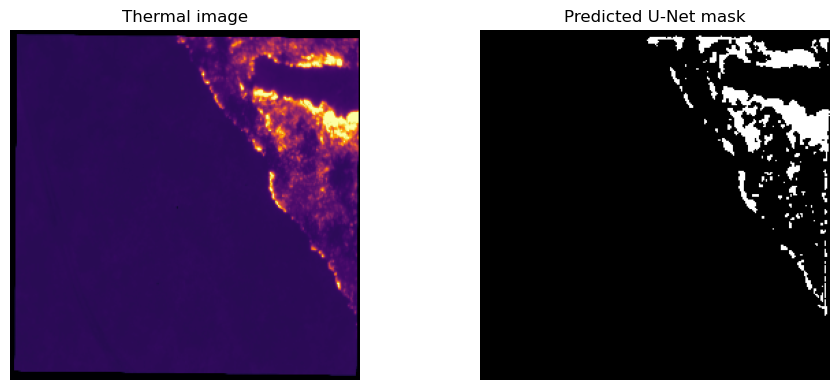

Foreground percentage: 5.37 %


In [41]:

sample_path = geo_images[0]

with rasterio.open(sample_path) as src:
    thermal = src.read(1).astype(np.float32)

thermal[~np.isfinite(thermal)] = 0
thermal = cv2.resize(thermal, (256, 256))

lo, hi = thermal.min(), thermal.max()
thermal = (
    (thermal - lo) / (hi - lo)
    if hi > lo else np.zeros_like(thermal)
)

rgb = np.repeat(thermal[..., None], 3, axis=2)

tensor = torch.from_numpy(
    rgb.transpose(2, 0, 1).copy()
).float().unsqueeze(0).to(device)

with torch.no_grad():
    logits = model(tensor)
    probability = torch.sigmoid(logits)[0, 0].cpu().numpy()

predicted_mask = (probability > 0.3).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(thermal, cmap="inferno")
axes[0].set_title("Thermal image")
axes[1].imshow(predicted_mask, cmap="gray")
axes[1].set_title("Predicted U-Net mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Foreground percentage:",
      round(100 * predicted_mask.mean(), 2), "%")


In [42]:

from pathlib import Path
import numpy as np
import rasterio
import cv2
import torch
from tqdm.auto import tqdm

MASK_DIR = Path(r"D:\archive\unet_pseudo_masks")
MASK_DIR.mkdir(parents=True, exist_ok=True)

model.eval()
saved_count = 0
failed_files = []

for path in tqdm(geo_images, desc="Generating provisional masks"):
    try:
        with rasterio.open(path) as src:
            thermal = src.read(1).astype(np.float32)

        # Handle invalid pixels
        valid = np.isfinite(thermal)
        if not valid.any():
            failed_files.append((str(path), "No valid pixels"))
            continue

        thermal[~valid] = 0

        # Same preliminary preprocessing as the single-image test
        resized = cv2.resize(thermal, (256, 256))
        lo, hi = resized.min(), resized.max()

        if hi > lo:
            normalized = (resized - lo) / (hi - lo)
        else:
            normalized = np.zeros_like(resized)

        rgb = np.repeat(normalized[..., None], 3, axis=2)
        tensor = torch.from_numpy(
            rgb.transpose(2, 0, 1).copy()
        ).float().unsqueeze(0).to(device)

        with torch.no_grad():
            logits = model(tensor)
            probability = torch.sigmoid(logits)[0, 0].cpu().numpy()

        mask = (probability > 0.3).astype(np.uint8) * 255

        # Preserve folder structure to prevent filename collisions
        relative_path = path.relative_to(DATASET_PATH)
        output_path = MASK_DIR / relative_path.parent / (
            path.stem + "_mask.png"
        )
        output_path.parent.mkdir(parents=True, exist_ok=True)

        if not cv2.imwrite(str(output_path), mask):
            failed_files.append((str(path), "Mask save failed"))
            continue

        saved_count += 1

    except Exception as exc:
        failed_files.append((str(path), str(exc)))

print("Masks saved:", saved_count)
print("Failed images:", len(failed_files))

if failed_files:
    print("First failures:")
    for item in failed_files[:10]:
        print(item)


Generating provisional masks:   0%|          | 0/794 [00:00<?, ?it/s]

Masks saved: 794
Failed images: 0


In [43]:

mask_files = sorted(MASK_DIR.rglob("*_mask.png"))

print("Saved mask files:", len(mask_files))
print("Example masks:")
for path in mask_files[:10]:
    print(path)


Saved mask files: 794
Example masks:
D:\archive\unet_pseudo_masks\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0529_ref_geo_mask.png
D:\archive\unet_pseudo_masks\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0530_ref_geo_mask.png
D:\archive\unet_pseudo_masks\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0531_ref_geo_mask.png
D:\archive\unet_pseudo_masks\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0532_ref_geo_mask.png
D:\archive\unet_pseudo_masks\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0533_ref_geo_mask.png
D:\archive\unet_pseudo_masks\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0534_ref_geo_mask.png
D:\archive\unet_pseudo_masks\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0535_ref_geo_mask.png
D:\archive\unet_pseudo_masks\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0536_ref_geo_mask.png
D:\archive\unet_pseudo_masks\Hanna Hammock\plot 1\duringburn\geo_th

In [44]:

import cv2
import numpy as np
from pathlib import Path

mask_files = sorted(MASK_DIR.rglob("*_mask.png"))

for path in mask_files[:5]:
    mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    print(
        path.name,
        "| Shape:", mask.shape if mask is not None else None,
        "| Unique values:", np.unique(mask) if mask is not None else None
    )


IRX_0529_ref_geo_mask.png | Shape: (256, 256) | Unique values: [  0 255]
IRX_0530_ref_geo_mask.png | Shape: (256, 256) | Unique values: [  0 255]
IRX_0531_ref_geo_mask.png | Shape: (256, 256) | Unique values: [  0 255]
IRX_0532_ref_geo_mask.png | Shape: (256, 256) | Unique values: [  0 255]
IRX_0533_ref_geo_mask.png | Shape: (256, 256) | Unique values: [  0 255]


In [45]:

import re
from pathlib import Path

sequence_groups = {}

for mask_path in mask_files:
    relative = mask_path.relative_to(MASK_DIR)
    parent = relative.parent

    # Each original thermal folder is kept as a separate sequence group
    sequence_groups.setdefault(parent, []).append(mask_path)

def frame_number(path):
    match = re.search(r"IRX_(\d+)_ref_geo_mask", path.name, re.IGNORECASE)
    return int(match.group(1)) if match else -1

for folder, paths in sorted(sequence_groups.items(), key=lambda x: str(x[0])):
    paths.sort(key=frame_number)
    print(folder, ":", len(paths), "frames")


Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius : 296 frames
Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part1 : 322 frames
Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part2 : 176 frames


In [46]:

total_sequences = 0

for folder, paths in sequence_groups.items():
    paths.sort(key=frame_number)
    numbers = [frame_number(p) for p in paths]

    consecutive_windows = 0
    for i in range(len(numbers) - 5):
        window = numbers[i:i + 6]
        if all(b == a + 1 for a, b in zip(window, window[1:])):
            consecutive_windows += 1

    print(folder, "->", consecutive_windows, "valid windows")
    total_sequences += consecutive_windows

print("\nTotal valid six-frame windows:", total_sequences)


Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius -> 291 valid windows
Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part1 -> 317 valid windows
Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part2 -> 171 valid windows

Total valid six-frame windows: 779


In [47]:

import cv2
import numpy as np
from pathlib import Path

MASK_DIR = Path(r"D:\archive\unet_pseudo_masks")

def get_frame_number(path):
    import re
    match = re.search(r"IRX_(\d+)_ref_geo_mask", path.name, re.I)
    return int(match.group(1)) if match else -1

mask_groups = {}

for mask_path in MASK_DIR.rglob("*_mask.png"):
    relative = mask_path.relative_to(MASK_DIR)
    mask_groups.setdefault(relative.parent, []).append(mask_path)

for folder in mask_groups:
    mask_groups[folder].sort(key=get_frame_number)

print("Number of groups:", len(mask_groups))

for folder, paths in sorted(mask_groups.items(), key=lambda x: str(x[0])):
    sample = cv2.imread(str(paths[0]), cv2.IMREAD_GRAYSCALE)

    print("\nGroup:", folder)
    print("Frames:", len(paths))
    print("Sample shape:", sample.shape if sample is not None else None)
    print("Sample values:", np.unique(sample) if sample is not None else None)


Number of groups: 3

Group: Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius
Frames: 296
Sample shape: (256, 256)
Sample values: [  0 255]

Group: Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part1
Frames: 322
Sample shape: (256, 256)
Sample values: [  0 255]

Group: Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part2
Frames: 176
Sample shape: (256, 256)
Sample values: [  0 255]


In [48]:

SEQ_LEN = 5
X_sequences = []
y_targets = []
sequence_group_ids = []

for group_id, (folder, paths) in enumerate(
    sorted(mask_groups.items(), key=lambda x: str(x[0]))
):
    numbers = [get_frame_number(p) for p in paths]

    masks = []
    for path in paths:
        mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
        if mask is None or mask.shape != (256, 256):
            raise ValueError(f"Invalid mask: {path}")
        masks.append((mask > 127).astype(np.float32))

    for i in range(len(masks) - SEQ_LEN):
        window_numbers = numbers[i:i + SEQ_LEN + 1]

        # Require six consecutive frame numbers
        if not all(
            b == a + 1
            for a, b in zip(window_numbers, window_numbers[1:])
        ):
            continue

        X_sequences.append(masks[i:i + SEQ_LEN])
        y_targets.append(masks[i + SEQ_LEN])
        sequence_group_ids.append(group_id)

X = np.asarray(X_sequences, dtype=np.float32)[..., None]
y = np.asarray(y_targets, dtype=np.float32)[..., None]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Samples:", len(X))


X shape: (779, 5, 256, 256, 1)
y shape: (779, 256, 256, 1)
Samples: 779


In [49]:

import numpy as np
import torch

# Convert from NumPy arrays to PyTorch format
X_torch = torch.from_numpy(
    np.ascontiguousarray(X.transpose(0, 1, 4, 2, 3))
).float()

y_torch = torch.from_numpy(
    np.ascontiguousarray(y.transpose(0, 3, 1, 2))
).float()

print("ConvLSTM input:", X_torch.shape)
print("ConvLSTM target:", y_torch.shape)
print("Input values:", torch.unique(X_torch))
print("Target values:", torch.unique(y_torch))


ConvLSTM input: torch.Size([779, 5, 1, 256, 256])
ConvLSTM target: torch.Size([779, 1, 256, 256])
Input values: tensor([0., 1.])
Target values: tensor([0., 1.])


In [50]:

print("Input memory (MB):",
      round(X_torch.numel() * X_torch.element_size() / 1024**2, 1))
print("Target memory (MB):",
      round(y_torch.numel() * y_torch.element_size() / 1024**2, 1))
print("Training device: CPU")


Input memory (MB): 973.8
Target memory (MB): 194.8
Training device: CPU


In [51]:

import torch.nn as nn

class ConvLSTMCell(nn.Module):
    def __init__(self, input_channels, hidden_channels, kernel_size=3):
        super().__init__()
        self.hidden_channels = hidden_channels

        self.gates = nn.Conv2d(
            input_channels + hidden_channels,
            4 * hidden_channels,
            kernel_size=kernel_size,
            padding=kernel_size // 2
        )

    def forward(self, x, state):
        h, c = state
        gates = self.gates(torch.cat([x, h], dim=1))
        i, f, o, g = torch.chunk(gates, 4, dim=1)

        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        o = torch.sigmoid(o)
        g = torch.tanh(g)

        c = f * c + i * g
        h = o * torch.tanh(c)
        return h, c

    def init_state(self, batch, height, width, device):
        shape = (batch, self.hidden_channels, height, width)
        return (
            torch.zeros(shape, device=device),
            torch.zeros(shape, device=device)
        )


class ConvLSTMForecast(nn.Module):
    def __init__(self, hidden_channels=16):
        super().__init__()
        self.hidden_channels = hidden_channels
        self.cell = ConvLSTMCell(1, hidden_channels)
        self.output_layer = nn.Conv2d(hidden_channels, 1, kernel_size=1)

    def forward(self, x):
        # x: (batch, time, channels, height, width)
        batch, time, _, height, width = x.shape

        h, c = self.cell.init_state(
            batch, height, width, x.device
        )

        for t in range(time):
            h, c = self.cell(x[:, t], (h, c))

        return self.output_layer(h)  # logits, not probabilities


device = torch.device("cpu")
convlstm = ConvLSTMForecast(hidden_channels=16).to(device)

print("ConvLSTM model created.")
print("Parameters:", sum(p.numel() for p in convlstm.parameters()))


ConvLSTM model created.
Parameters: 9873


In [52]:

import numpy as np
import cv2
import re
from pathlib import Path
import re
import cv2
import numpy as np

MASK_DIR = Path(r"D:\archive\unet_pseudo_masks")

def get_frame_number(path):
    match = re.search(
        r"IRX_(\d+)_ref_geo_mask",
        path.name,
        re.IGNORECASE
    )
    return int(match.group(1)) if match else -1

mask_groups = {}

for path in MASK_DIR.rglob("*_mask.png"):
    relative = path.relative_to(MASK_DIR)
    mask_groups.setdefault(relative.parent, []).append(path)

for folder in mask_groups:
    mask_groups[folder].sort(key=get_frame_number)

group_items = sorted(
    mask_groups.items(),
    key=lambda item: str(item[0])
)

print("Number of groups:", len(group_items))

for i, (folder, paths) in enumerate(group_items):
    print(i, folder, len(paths))

assert len(group_items) == 3, "Expected three mask groups."

from pathlib import Path

SEQ_LEN = 5

def get_frame_number(path):
    match = re.search(
        r"IRX_(\d+)_ref_geo_mask",
        path.name,
        re.IGNORECASE
    )
    return int(match.group(1)) if match else -1

def load_masks_for_group(paths):
    paths = sorted(paths, key=get_frame_number)
    numbers = [get_frame_number(p) for p in paths]

    masks = []
    for path in paths:
        mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
        if mask is None or mask.shape != (256, 256):
            raise ValueError(f"Invalid mask: {path}")
        masks.append((mask > 127).astype(np.float32))

    return numbers, masks

group_items = sorted(mask_groups.items(), key=lambda item: str(item[0]))

# Verify the expected three groups
for i, (folder, paths) in enumerate(group_items):
    print(i, folder, len(paths))

assert len(group_items) == 3, "Expected three mask groups."


Number of groups: 3
0 Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius 296
1 Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part1 322
2 Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part2 176
0 Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius 296
1 Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part1 322
2 Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part2 176


In [53]:

def make_windows(paths, seq_len=5):
    paths = sorted(paths, key=get_frame_number)
    numbers = [get_frame_number(p) for p in paths]

    masks = []
    for path in paths:
        mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

        if mask is None or mask.shape != (256, 256):
            raise ValueError(f"Invalid mask: {path}")

        masks.append((mask > 127).astype(np.float32))

    X_list, y_list = [], []

    for i in range(len(masks) - seq_len):
        nums = numbers[i:i + seq_len + 1]

        if all(b == a + 1 for a, b in zip(nums, nums[1:])):
            X_list.append(masks[i:i + seq_len])
            y_list.append(masks[i + seq_len])

    if not X_list:
        return (
            np.empty((0, seq_len, 1, 256, 256), dtype=np.float32),
            np.empty((0, 1, 256, 256), dtype=np.float32)
        )

    X_arr = np.asarray(X_list, dtype=np.float32)[:, :, None, :, :]
    y_arr = np.asarray(y_list, dtype=np.float32)[:, None, :, :]

    return X_arr, y_arr


X_train, y_train = make_windows(group_items[0][1])
X_val, y_val = make_windows(group_items[1][1])
X_test, y_test = make_windows(group_items[2][1])

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)


Train: (291, 5, 1, 256, 256) (291, 1, 256, 256)
Validation: (317, 5, 1, 256, 256) (317, 1, 256, 256)
Test: (171, 5, 1, 256, 256) (171, 1, 256, 256)


In [54]:

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

assert len(X_train) > 0
assert len(X_val) > 0
assert len(X_test) > 0

print("Shapes verified. Ready for the next preparation step.")


Training samples: 291
Validation samples: 317
Test samples: 171
Shapes verified. Ready for the next preparation step.


In [55]:

import numpy as np

for name, targets in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    percentages = targets.mean(axis=(1, 2, 3)) * 100

    print(f"\n{name}")
    print("Samples:", len(targets))
    print("Mean foreground:", round(float(percentages.mean()), 2), "%")
    print("Minimum foreground:", round(float(percentages.min()), 2), "%")
    print("Maximum foreground:", round(float(percentages.max()), 2), "%")
    print("Nearly empty targets (<0.1%):",
          int(np.sum(percentages < 0.1)))



Train
Samples: 291
Mean foreground: 2.35 %
Minimum foreground: 0.42 %
Maximum foreground: 6.28 %
Nearly empty targets (<0.1%): 0

Validation
Samples: 317
Mean foreground: 0.71 %
Minimum foreground: 0.03 %
Maximum foreground: 6.86 %
Nearly empty targets (<0.1%): 38

Test
Samples: 171
Mean foreground: 2.71 %
Minimum foreground: 0.37 %
Maximum foreground: 4.63 %
Nearly empty targets (<0.1%): 0


In [56]:

import torch
from torch.utils.data import Dataset, DataLoader

class MaskSequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return (
            torch.from_numpy(self.X[idx]).float(),
            torch.from_numpy(self.y[idx]).float()
        )

train_ds = MaskSequenceDataset(X_train, y_train)
val_ds = MaskSequenceDataset(X_val, y_val)
test_ds = MaskSequenceDataset(X_test, y_test)

train_loader = DataLoader(
    train_ds, batch_size=2, shuffle=True, num_workers=0
)
val_loader = DataLoader(
    val_ds, batch_size=2, shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_ds, batch_size=2, shuffle=False, num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Training batches: 146
Validation batches: 159
Test batches: 86


In [59]:

device = torch.device("cpu")

convlstm = ConvLSTMForecast(hidden_channels=16).to(device)

print("Device:", device)
print("Parameters:", sum(p.numel() for p in convlstm.parameters()))


Device: cpu
Parameters: 9873


In [58]:

import torch
import torch.nn as nn
from pathlib import Path

device = torch.device("cpu")
convlstm = ConvLSTMForecast(hidden_channels=16).to(device)

optimizer = torch.optim.Adam(convlstm.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()

CHECKPOINT_OUT = Path(r"D:\archive\convlstm_retrained_best.pth")
best_val_loss = float("inf")
EPOCHS = 5

for epoch in range(EPOCHS):
    # Training
    convlstm.train()
    train_sum = 0.0

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()
        logits = convlstm(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        train_sum += loss.item() * xb.size(0)

    train_loss = train_sum / len(train_ds)

    # Validation
    convlstm.eval()
    val_sum = 0.0

    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            logits = convlstm(xb)
            loss = criterion(logits, yb)
            val_sum += loss.item() * xb.size(0)

    val_loss = val_sum / len(val_ds)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(convlstm.state_dict(), CHECKPOINT_OUT)
        print("  Best checkpoint saved.")

print("\nTraining finished.")
print("Best validation loss:", round(best_val_loss, 4))
print("Checkpoint:", CHECKPOINT_OUT)


Epoch 1/5 | Train loss: 0.2089 | Validation loss: 0.0332
  Best checkpoint saved.
Epoch 2/5 | Train loss: 0.0476 | Validation loss: 0.0195
  Best checkpoint saved.
Epoch 3/5 | Train loss: 0.0350 | Validation loss: 0.0149
  Best checkpoint saved.
Epoch 4/5 | Train loss: 0.0300 | Validation loss: 0.0112
  Best checkpoint saved.
Epoch 5/5 | Train loss: 0.0274 | Validation loss: 0.0102
  Best checkpoint saved.

Training finished.
Best validation loss: 0.0102
Checkpoint: D:\archive\convlstm_retrained_best.pth


In [61]:

convlstm.load_state_dict(
    torch.load(CHECKPOINT_OUT, map_location=device, weights_only=True)
)
convlstm.eval()

intersection = 0
union = 0
correct = 0
total_pixels = 0
test_loss_sum = 0.0
threshold = 0.3

with torch.no_grad():
    for xb, yb in test_loader:
        logits = convlstm(xb.to(device))
        targets = yb.to(device)

        test_loss_sum += (
            criterion(logits, targets).item() * xb.size(0)
        )

        pred = (torch.sigmoid(logits) > threshold)
        truth = targets > 0.5

        intersection += (pred & truth).sum().item()
        union += (pred | truth).sum().item()
        correct += (pred == truth).sum().item()
        total_pixels += truth.numel()

test_loss = test_loss_sum / len(test_ds)
iou = intersection / union if union else 1.0
dice = (
    2 * intersection / (pred.sum().item() + truth.sum().item())
    if False else None
)

print("Test BCE loss:", round(test_loss, 4))
print("Test IoU:", round(iou, 4))
print("Test pixel accuracy:", round(correct / total_pixels, 4))


Test BCE loss: 0.0326
Test IoU: 0.692
Test pixel accuracy: 0.9898


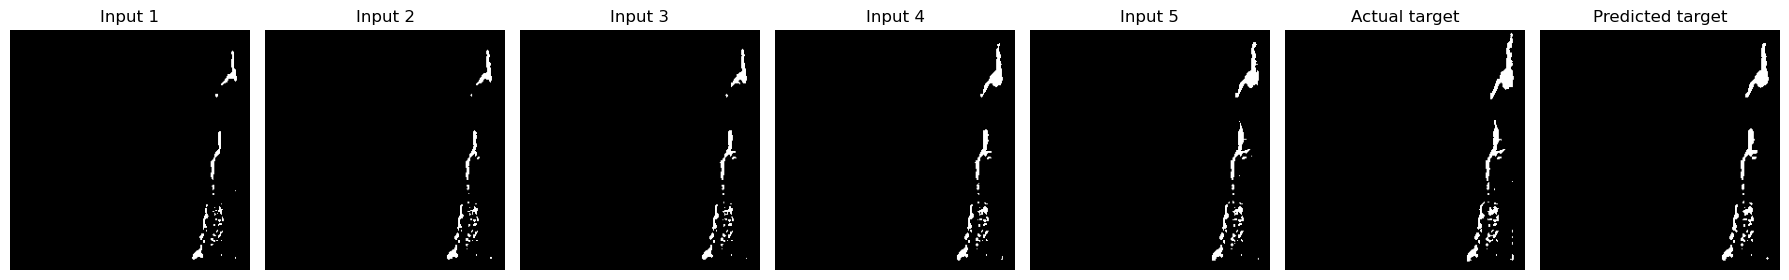

Predicted foreground: 1.81 %
Target foreground: 2.04 %


In [62]:

import torch
import numpy as np
import matplotlib.pyplot as plt

device = torch.device("cpu")

# Load the best saved checkpoint
convlstm.load_state_dict(
    torch.load(
        r"D:\archive\convlstm_retrained_best.pth",
        map_location=device,
        weights_only=True
    )
)
convlstm.eval()

# Select one test sample
sample_index = 0
input_sequence = torch.from_numpy(
    X_test[sample_index:sample_index + 1]
).float()

actual_mask = y_test[sample_index, 0]

with torch.no_grad():
    logits = convlstm(input_sequence.to(device))
    probability = torch.sigmoid(logits)[0, 0].cpu().numpy()

predicted_mask = (probability > 0.3).astype(np.uint8)

# Show the five input masks, the target, and the prediction
fig, axes = plt.subplots(1, 7, figsize=(18, 4))

for i in range(5):
    axes[i].imshow(X_test[sample_index, i, 0], cmap="gray", vmin=0, vmax=1)
    axes[i].set_title(f"Input {i + 1}")
    axes[i].axis("off")

axes[5].imshow(actual_mask, cmap="gray", vmin=0, vmax=1)
axes[5].set_title("Actual target")
axes[5].axis("off")

axes[6].imshow(predicted_mask, cmap="gray", vmin=0, vmax=1)
axes[6].set_title("Predicted target")
axes[6].axis("off")

plt.tight_layout()
plt.show()

print("Predicted foreground:",
      round(100 * predicted_mask.mean(), 2), "%")
print("Target foreground:",
      round(100 * actual_mask.mean(), 2), "%")


In [63]:

import numpy as np
import torch

convlstm.eval()

intersection = 0
pred_pixels = 0
target_pixels = 0
union = 0

base_intersection = 0
base_pred_pixels = 0
base_target_pixels = 0
base_union = 0

threshold = 0.3

with torch.no_grad():
    for xb, yb in test_loader:
        logits = convlstm(xb.to(device))
        pred = torch.sigmoid(logits) > threshold
        target = yb.to(device) > 0.5

        intersection += (pred & target).sum().item()
        pred_pixels += pred.sum().item()
        target_pixels += target.sum().item()
        union += (pred | target).sum().item()

        # Baseline: use the last input mask as the next mask
        baseline = xb[:, -1] > 0.5

        base_intersection += (baseline & target).sum().item()
        base_pred_pixels += baseline.sum().item()
        base_target_pixels += target.sum().item()
        base_union += (baseline | target).sum().item()

dice = (
    2 * intersection / (pred_pixels + target_pixels)
    if pred_pixels + target_pixels else 1.0
)
iou = intersection / union if union else 1.0

baseline_dice = (
    2 * base_intersection / (base_pred_pixels + base_target_pixels)
    if base_pred_pixels + base_target_pixels else 1.0
)
baseline_iou = base_intersection / base_union if base_union else 1.0

print("ConvLSTM Dice:", round(dice, 4))
print("ConvLSTM IoU:", round(iou, 4))
print("Persistence Dice:", round(baseline_dice, 4))
print("Persistence IoU:", round(baseline_iou, 4))


ConvLSTM Dice: 0.818
ConvLSTM IoU: 0.692
Persistence Dice: 0.8524
Persistence IoU: 0.7428


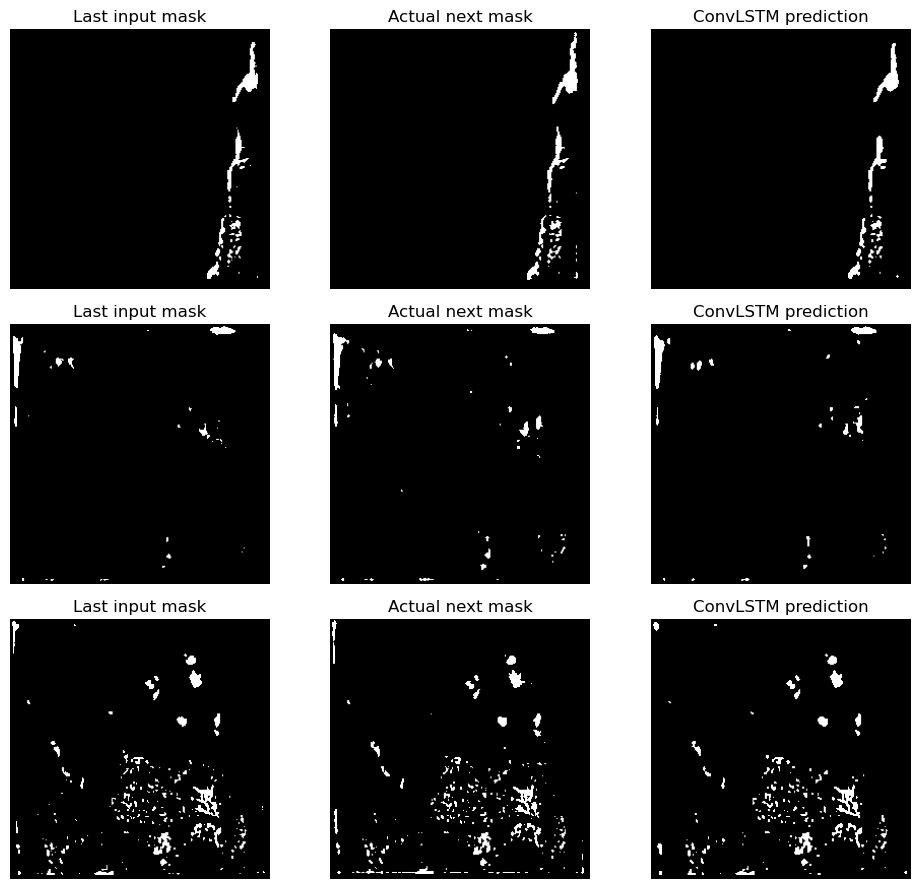

In [64]:

import matplotlib.pyplot as plt
import numpy as np
import torch

convlstm.eval()
indices = [0, len(X_test) // 3, 2 * len(X_test) // 3]

fig, axes = plt.subplots(len(indices), 3, figsize=(10, 9))

with torch.no_grad():
    for row, idx in enumerate(indices):
        xb = torch.from_numpy(X_test[idx:idx+1]).float()
        target = y_test[idx, 0]

        logits = convlstm(xb.to(device))
        prediction = (
            torch.sigmoid(logits)[0, 0].cpu().numpy() > 0.3
        ).astype(np.uint8)

        last_mask = X_test[idx, -1, 0]

        axes[row, 0].imshow(last_mask, cmap="gray", vmin=0, vmax=1)
        axes[row, 0].set_title("Last input mask")

        axes[row, 1].imshow(target, cmap="gray", vmin=0, vmax=1)
        axes[row, 1].set_title("Actual next mask")

        axes[row, 2].imshow(prediction, cmap="gray", vmin=0, vmax=1)
        axes[row, 2].set_title("ConvLSTM prediction")

        for ax in axes[row]:
            ax.axis("off")

plt.tight_layout()
plt.show()


In [65]:

import numpy as np
import torch

convlstm.eval()
threshold = 0.3

actual_changes = []
predicted_changes = []
persistence_changes = []

with torch.no_grad():
    for xb, yb in test_loader:
        logits = convlstm(xb.to(device))
        predictions = (
            torch.sigmoid(logits).cpu().numpy() > threshold
        )

        targets = yb.numpy() > 0.5
        last_masks = xb[:, -1].numpy() > 0.5

        # Foreground fraction for each sample
        pred_area = predictions.mean(axis=(1, 2, 3))
        actual_area = targets.mean(axis=(1, 2, 3))
        last_area = last_masks.mean(axis=(1, 2, 3))

        actual_changes.extend(actual_area - last_area)
        predicted_changes.extend(pred_area - last_area)
        persistence_changes.extend(
            np.zeros_like(actual_area)
        )

actual_changes = np.asarray(actual_changes)
predicted_changes = np.asarray(predicted_changes)

print("Mean actual area change (% points):",
      round(100 * actual_changes.mean(), 4))
print("Mean ConvLSTM area change (% points):",
      round(100 * predicted_changes.mean(), 4))

mae_convlstm = np.mean(
    np.abs(predicted_changes - actual_changes)
)
mae_persistence = np.mean(np.abs(actual_changes))

print("ConvLSTM area-change MAE (% points):",
      round(100 * mae_convlstm, 4))
print("Persistence area-change MAE (% points):",
      round(100 * mae_persistence, 4))


Mean actual area change (% points): 0.0063
Mean ConvLSTM area change (% points): 0.1935
ConvLSTM area-change MAE (% points): 0.3443
Persistence area-change MAE (% points): 0.2736


In [66]:

import numpy as np
import torch

convlstm.eval()
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6]

results = []

with torch.no_grad():
    for threshold in thresholds:
        area_change_errors = []
        intersections = 0
        unions = 0

        for xb, yb in test_loader:
            logits = convlstm(xb.to(device))
            probabilities = torch.sigmoid(logits).cpu().numpy()

            pred = probabilities > threshold
            target = yb.numpy() > 0.5
            last_mask = xb[:, -1].numpy() > 0.5

            pred_area = pred.mean(axis=(1, 2, 3))
            target_area = target.mean(axis=(1, 2, 3))
            last_area = last_mask.mean(axis=(1, 2, 3))

            area_change_errors.extend(
                np.abs((pred_area - last_area) -
                       (target_area - last_area))
            )

            intersections += np.logical_and(pred, target).sum()
            unions += np.logical_or(pred, target).sum()

        area_mae = np.mean(area_change_errors)
        iou = intersections / unions if unions else 1.0

        results.append((threshold, area_mae, iou))

for threshold, area_mae, iou in results:
    print(
        f"Threshold={threshold:.1f} | "
        f"Area-change MAE={area_mae:.5f} | IoU={iou:.4f}"
    )


Threshold=0.2 | Area-change MAE=0.00507 | IoU=0.6661
Threshold=0.3 | Area-change MAE=0.00344 | IoU=0.6920
Threshold=0.4 | Area-change MAE=0.00295 | IoU=0.7025
Threshold=0.5 | Area-change MAE=0.00316 | IoU=0.7024
Threshold=0.6 | Area-change MAE=0.00401 | IoU=0.6991


In [67]:

import numpy as np
import torch

convlstm.eval()
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6]
validation_results = []

with torch.no_grad():
    for threshold in thresholds:
        intersection = 0
        union = 0
        area_errors = []

        for xb, yb in val_loader:
            logits = convlstm(xb.to(device))
            probabilities = torch.sigmoid(logits).cpu().numpy()

            pred = probabilities > threshold
            target = yb.numpy() > 0.5
            last_mask = xb[:, -1].numpy() > 0.5

            intersection += np.logical_and(pred, target).sum()
            union += np.logical_or(pred, target).sum()

            pred_area = pred.mean(axis=(1, 2, 3))
            target_area = target.mean(axis=(1, 2, 3))
            last_area = last_mask.mean(axis=(1, 2, 3))

            area_errors.extend(
                np.abs(
                    (pred_area - last_area)
                    - (target_area - last_area)
                )
            )

        val_iou = intersection / union if union else 1.0
        val_area_mae = np.mean(area_errors)

        validation_results.append(
            (threshold, val_iou, val_area_mae)
        )

for threshold, val_iou, val_area_mae in validation_results:
    print(
        f"Threshold={threshold:.1f} | "
        f"Validation IoU={val_iou:.4f} | "
        f"Area-change MAE={val_area_mae:.5f}"
    )


Threshold=0.2 | Validation IoU=0.6998 | Area-change MAE=0.00147
Threshold=0.3 | Validation IoU=0.7204 | Area-change MAE=0.00108
Threshold=0.4 | Validation IoU=0.7300 | Area-change MAE=0.00094
Threshold=0.5 | Validation IoU=0.7340 | Area-change MAE=0.00093
Threshold=0.6 | Validation IoU=0.7359 | Area-change MAE=0.00102


In [68]:

import numpy as np
import torch

convlstm.eval()
threshold = 0.5

intersection = 0
union = 0
pred_pixels = 0
target_pixels = 0

base_intersection = 0
base_union = 0
base_pred_pixels = 0
base_target_pixels = 0

actual_area_changes = []
predicted_area_changes = []

with torch.no_grad():
    for xb, yb in test_loader:
        logits = convlstm(xb.to(device))
        pred = torch.sigmoid(logits).cpu().numpy() > threshold
        target = yb.numpy() > 0.5
        last_mask = xb[:, -1].numpy() > 0.5

        intersection += np.logical_and(pred, target).sum()
        union += np.logical_or(pred, target).sum()
        pred_pixels += pred.sum()
        target_pixels += target.sum()

        base_intersection += np.logical_and(last_mask, target).sum()
        base_union += np.logical_or(last_mask, target).sum()
        base_pred_pixels += last_mask.sum()
        base_target_pixels += target.sum()

        pred_area = pred.mean(axis=(1, 2, 3))
        target_area = target.mean(axis=(1, 2, 3))
        last_area = last_mask.mean(axis=(1, 2, 3))

        predicted_area_changes.extend(pred_area - last_area)
        actual_area_changes.extend(target_area - last_area)

dice = (
    2 * intersection / (pred_pixels + target_pixels)
    if pred_pixels + target_pixels else 1.0
)
iou = intersection / union if union else 1.0

baseline_dice = (
    2 * base_intersection / (base_pred_pixels + base_target_pixels)
    if base_pred_pixels + base_target_pixels else 1.0
)
baseline_iou = base_intersection / base_union if base_union else 1.0

area_mae = np.mean(
    np.abs(np.array(predicted_area_changes) -
           np.array(actual_area_changes))
)
baseline_area_mae = np.mean(np.abs(actual_area_changes))

print("TEST RESULTS — threshold 0.5")
print("ConvLSTM Dice:", round(dice, 4))
print("ConvLSTM IoU:", round(iou, 4))
print("Persistence Dice:", round(baseline_dice, 4))
print("Persistence IoU:", round(baseline_iou, 4))
print("ConvLSTM area-change MAE (% points):",
      round(100 * area_mae, 5))
print("Persistence area-change MAE (% points):",
      round(100 * baseline_area_mae, 5))


TEST RESULTS — threshold 0.5
ConvLSTM Dice: 0.8252
ConvLSTM IoU: 0.7024
Persistence Dice: 0.8524
Persistence IoU: 0.7428
ConvLSTM area-change MAE (% points): 0.3156
Persistence area-change MAE (% points): 0.27361


In [69]:

import numpy as np

print("Train input shape:", X_train.shape)
print("Train target shape:", y_train.shape)
print("Validation input shape:", X_val.shape)
print("Validation target shape:", y_val.shape)
print("Test input shape:", X_test.shape)
print("Test target shape:", y_test.shape)

print("\nValue ranges")
print("X_train:", np.nanmin(X_train), np.nanmax(X_train))
print("y_train:", np.nanmin(y_train), np.nanmax(y_train))

print("\nForeground percentages")
print("Last input:",
      round(100 * X_test[:, -1].mean(), 3), "%")
print("Test target:",
      round(100 * y_test.mean(), 3), "%")

print("\nNon-finite values")
print("X_train:", np.isfinite(X_train).all())
print("y_train:", np.isfinite(y_train).all())
print("X_test:", np.isfinite(X_test).all())
print("y_test:", np.isfinite(y_test).all())


Train input shape: (291, 5, 1, 256, 256)
Train target shape: (291, 1, 256, 256)
Validation input shape: (317, 5, 1, 256, 256)
Validation target shape: (317, 1, 256, 256)
Test input shape: (171, 5, 1, 256, 256)
Test target shape: (171, 1, 256, 256)

Value ranges
X_train: 0.0 1.0
y_train: 0.0 1.0

Foreground percentages
Last input: 2.707 %
Test target: 2.713 %

Non-finite values
X_train: True
y_train: True
X_test: True
y_test: True


In [8]:

import numpy as np
import matplotlib.pyplot as plt

indices = [0, len(X_train) // 2, len(X_train) - 1]

fig, axes = plt.subplots(3, 7, figsize=(16, 8))

for row, idx in enumerate(indices):
    for t in range(5):
        axes[row, t].imshow(
            X_train[idx, t, 0], cmap="gray", vmin=0, vmax=1
        )
        axes[row, t].set_title(f"Input {t + 1}")
        axes[row, t].axis("off")

    axes[row, 5].imshow(
        X_train[idx, -1, 0], cmap="gray", vmin=0, vmax=1
    )
    axes[row, 5].set_title("Last input")
    axes[row, 5].axis("off")

    axes[row, 6].imshow(
        y_train[idx, 0], cmap="gray", vmin=0, vmax=1
    )
    axes[row, 6].set_title("Target")
    axes[row, 6].axis("off")

plt.tight_layout()
plt.show()


NameError: name 'X_train' is not defined

In [71]:

import numpy as np

# Check whether the target differs from the last input
for name, X, Y in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test),
]:
    last_masks = X[:, -1, 0] > 0.5
    target_masks = Y[:, 0] > 0.5

    same = np.all(last_masks == target_masks, axis=(1, 2))
    iou_scores = []

    for a, b in zip(last_masks, target_masks):
        union = np.logical_or(a, b).sum()
        intersection = np.logical_and(a, b).sum()
        iou_scores.append(intersection / union if union else 1.0)

    print(f"\n{name}")
    print("Samples:", len(X))
    print("Identical last-input/target masks:", int(same.sum()))
    print("Mean IoU with last input:", round(float(np.mean(iou_scores)), 4))
    print("Mean target foreground (%):", round(float(target_masks.mean() * 100), 3))



Train
Samples: 291
Identical last-input/target masks: 0
Mean IoU with last input: 0.7794
Mean target foreground (%): 2.35

Validation
Samples: 317
Identical last-input/target masks: 1
Mean IoU with last input: 0.8092
Mean target foreground (%): 0.711

Test
Samples: 171
Identical last-input/target masks: 0
Mean IoU with last input: 0.6975
Mean target foreground (%): 2.713


In [ ]:
cd "C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main"
.\.venv\Scripts\Activate.ps1
python -m uvicorn backend.app:app --reload --host 127.0.0.1 --port 8000

In [5]:

from pathlib import Path

DATASET_PATH = Path(r"D:\archive\Hanna Hammock")

group_folders = [
    DATASET_PATH / "plot 1" / "duringburn" / "geo_thermal_tiff_celsius",
    DATASET_PATH / "plot 2" / "duringburn" / "geo_thermal_tiff_celsius" / "part1",
    DATASET_PATH / "plot 2" / "duringburn" / "geo_thermal_tiff_celsius" / "part2",
]

for folder in group_folders:
    images = sorted(
        p for p in folder.iterdir()
        if p.suffix.lower() in (".tif", ".tiff")
    ) if folder.exists() else []

    print("\nFolder:", folder)
    print("Exists:", folder.exists())
    print("TIFF images:", len(images))
    if images:
        print("First:", images[0].name)
        print("Last:", images[-1].name)



Folder: D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius
Exists: True
TIFF images: 296
First: IRX_0529_ref_geo.TIFF
Last: IRX_0824_ref_geo.TIFF

Folder: D:\archive\Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part1
Exists: True
TIFF images: 322
First: IRX_0826_ref_geo.TIFF
Last: IRX_1147_ref_geo.TIFF

Folder: D:\archive\Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part2
Exists: True
TIFF images: 176
First: IRX_1171_ref_geo.TIFF
Last: IRX_1346_ref_geo.TIFF


In [6]:

from pathlib import Path

# Recreate the three groups
group_items = []

for folder in group_folders:
    paths = sorted(
        p for p in folder.iterdir()
        if p.suffix.lower() in (".tif", ".tiff")
    )

    group_items.append((folder, paths))

# Print the available groups
for i, (folder, paths) in enumerate(group_items):
    print(f"Group {i}: {folder}")
    print("Frames:", len(paths))

# Assign separate groups to each split
train_paths = group_items[0][1]
val_paths = group_items[1][1]
test_paths = group_items[2][1]

print("\nAssigned groups:")
print("Train:", len(train_paths))
print("Validation:", len(val_paths))
print("Test:", len(test_paths))


Group 0: D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius
Frames: 296
Group 1: D:\archive\Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part1
Frames: 322
Group 2: D:\archive\Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part2
Frames: 176

Assigned groups:
Train: 296
Validation: 322
Test: 176


In [11]:

from pathlib import Path
import numpy as np
from PIL import Image

MASK_ROOT = Path(r"D:\archive\unet_pseudo_masks")
SEQ_LEN = 5
IMG_SIZE = 256

def load_mask(path):
    mask = np.array(Image.open(path).convert("L"))
    if mask.shape != (IMG_SIZE, IMG_SIZE):
        raise ValueError(f"Unexpected mask size: {path} {mask.shape}")
    return (mask > 127).astype(np.float32)

def build_windows(source_paths):
    X_list, Y_list = [], []

    for source in source_paths:
        # Match the TIFF to its saved U-Net mask
        relative = source.relative_to(Path(r"D:\archive\Hanna Hammock"))
        mask_path = (
            MASK_ROOT / relative.parent /
            f"{source.stem}_mask.png"
        )

        if not mask_path.exists():
            raise FileNotFoundError(f"Missing mask: {mask_path}")

        # Collect masks in the existing chronological order
        # (each split is a single source group)
        # For efficient loading, this cell is run per group.
        pass

    return X_list, Y_list


In [10]:

from pathlib import Path

MASK_ROOT = Path(r"D:\archive\unet_pseudo_masks")
SOURCE_ROOT = Path(r"D:\archive\Hanna Hammock")

for source in train_paths[:3]:
    relative = source.relative_to(SOURCE_ROOT)
    mask_path = MASK_ROOT / relative.parent / f"{source.stem}_mask.png"

    print("TIFF:", source.name)
    print("Expected mask:", mask_path)
    print("Mask exists:", mask_path.exists())
    print()


TIFF: IRX_0529_ref_geo.TIFF
Expected mask: D:\archive\unet_pseudo_masks\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0529_ref_geo_mask.png
Mask exists: False

TIFF: IRX_0530_ref_geo.TIFF
Expected mask: D:\archive\unet_pseudo_masks\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0530_ref_geo_mask.png
Mask exists: False

TIFF: IRX_0531_ref_geo.TIFF
Expected mask: D:\archive\unet_pseudo_masks\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0531_ref_geo_mask.png
Mask exists: False



In [12]:

from pathlib import Path

MASK_ROOT = Path(r"D:\archive\unet_pseudo_masks")

print("Mask root exists:", MASK_ROOT.exists())

if MASK_ROOT.exists():
    mask_files = list(MASK_ROOT.rglob("*_mask.png"))
    print("Total masks found:", len(mask_files))

    for path in mask_files[:10]:
        print(path)
else:
    print("The mask folder was not found.")


Mask root exists: True
Total masks found: 794
D:\archive\unet_pseudo_masks\Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part1\IRX_0826_ref_geo_mask.png
D:\archive\unet_pseudo_masks\Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part1\IRX_0827_ref_geo_mask.png
D:\archive\unet_pseudo_masks\Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part1\IRX_0828_ref_geo_mask.png
D:\archive\unet_pseudo_masks\Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part1\IRX_0829_ref_geo_mask.png
D:\archive\unet_pseudo_masks\Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part1\IRX_0830_ref_geo_mask.png
D:\archive\unet_pseudo_masks\Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part1\IRX_0831_ref_geo_mask.png
D:\archive\unet_pseudo_masks\Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part1\IRX_0832_ref_geo_mask.png
D:\archive\unet_pseudo_masks\Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part1\IRX_0833_ref_geo_mask.png
D:\archive

In [13]:

from pathlib import Path
from PIL import Image
import numpy as np

SOURCE_ROOT = Path(r"D:\archive\Hanna Hammock")
MASK_ROOT = Path(r"D:\archive\unet_pseudo_masks\Hanna Hammock")
SEQ_LEN = 5
IMG_SIZE = 256

def get_mask_path(tiff_path):
    relative = tiff_path.relative_to(SOURCE_ROOT)
    return MASK_ROOT / relative.parent / f"{tiff_path.stem}_mask.png"

def frame_number(path):
    # Example: IRX_0529_ref_geo.TIFF -> 529
    return int(path.name.split("_")[1])

def build_windows(source_paths):
    source_paths = sorted(source_paths, key=frame_number)
    X, Y = [], []

    # Cache masks and preserve source-frame identity
    loaded = []
    for path in source_paths:
        mask_path = get_mask_path(path)
        if not mask_path.exists():
            raise FileNotFoundError(f"Missing mask: {mask_path}")

        with Image.open(mask_path) as im:
            mask = np.asarray(im.convert("L"))

        if mask.shape != (IMG_SIZE, IMG_SIZE):
            raise ValueError(f"Wrong mask dimensions: {mask_path}")

        loaded.append((frame_number(path), (mask > 127).astype(np.float32)))

    for i in range(len(loaded) - SEQ_LEN):
        window = loaded[i:i + SEQ_LEN + 1]
        numbers = [item[0] for item in window]

        # Do not allow windows across missing frame numbers
        if not all(b == a + 1 for a, b in zip(numbers, numbers[1:])):
            continue

        X.append(np.stack([item[1] for item in window[:SEQ_LEN]]))
        Y.append(window[SEQ_LEN][1][None, :, :])

    return (
        np.asarray(X, dtype=np.float32)[:, :, None, :, :],
        np.asarray(Y, dtype=np.float32)
    )

X_train_new, y_train_new = build_windows(train_paths)
X_val_new, y_val_new = build_windows(val_paths)
X_test_new, y_test_new = build_windows(test_paths)

print("Train:", X_train_new.shape, y_train_new.shape)
print("Validation:", X_val_new.shape, y_val_new.shape)
print("Test:", X_test_new.shape, y_test_new.shape)


Train: (291, 5, 1, 256, 256) (291, 1, 256, 256)
Validation: (317, 5, 1, 256, 256) (317, 1, 256, 256)
Test: (171, 5, 1, 256, 256) (171, 1, 256, 256)


In [14]:

import torch
import torch.nn as nn
from pathlib import Path

# Recreate the architecture used for training
class ConvLSTMCell(nn.Module):
    def __init__(self, input_channels, hidden_channels, kernel_size=3):
        super().__init__()
        self.hidden_channels = hidden_channels
        padding = kernel_size // 2
        self.gates = nn.Conv2d(
            input_channels + hidden_channels,
            4 * hidden_channels,
            kernel_size,
            padding=padding
        )

    def forward(self, x, state):
        h, c = state
        gates = self.gates(torch.cat([x, h], dim=1))
        i, f, g, o = torch.chunk(gates, 4, dim=1)

        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        g = torch.tanh(g)
        o = torch.sigmoid(o)

        c = f * c + i * g
        h = o * torch.tanh(c)
        return h, c

    def init_state(self, batch, height, width, device):
        shape = (batch, self.hidden_channels, height, width)
        return (
            torch.zeros(shape, device=device),
            torch.zeros(shape, device=device)
        )

class ConvLSTMForecast(nn.Module):
    def __init__(self, hidden_channels=16):
        super().__init__()
        self.cell = ConvLSTMCell(1, hidden_channels)
        self.output_layer = nn.Conv2d(hidden_channels, 1, kernel_size=1)

    def forward(self, x):
        batch, steps, _, height, width = x.shape
        h, c = self.cell.init_state(batch, height, width, x.device)

        for t in range(steps):
            h, c = self.cell(x[:, t], (h, c))

        return self.output_layer(h)

device = torch.device("cpu")
checkpoint = Path(r"D:\archive\convlstm_retrained_best.pth")

assert checkpoint.exists(), f"Checkpoint not found: {checkpoint}"

model = ConvLSTMForecast(hidden_channels=16).to(device)
state = torch.load(checkpoint, map_location=device, weights_only=True)
model.load_state_dict(state)
model.eval()

print("Model loaded successfully.")
print("Checkpoint:", checkpoint)
print("Device:", device)


Model loaded successfully.
Checkpoint: D:\archive\convlstm_retrained_best.pth
Device: cpu


In [15]:

import numpy as np
import torch

# Use the rebuilt test arrays
X_eval = torch.from_numpy(X_test_new).float().to(device)
Y_eval = torch.from_numpy(y_test_new).float().to(device)

model.eval()
threshold = 0.5

intersection = union = 0
pred_pixels = target_pixels = 0
baseline_intersection = baseline_union = 0
baseline_pred_pixels = 0
area_errors = []
baseline_area_errors = []

with torch.no_grad():
    for start in range(0, len(X_eval), 2):
        xb = X_eval[start:start + 2]
        yb = Y_eval[start:start + 2]

        logits = model(xb)
        predictions = torch.sigmoid(logits) > threshold
        targets = yb > 0.5

        # Persistence baseline: predict the last input mask
        baseline = xb[:, -1] > 0.5

        intersection += (predictions & targets).sum().item()
        union += (predictions | targets).sum().item()
        pred_pixels += predictions.sum().item()
        target_pixels += targets.sum().item()

        baseline_intersection += (baseline & targets).sum().item()
        baseline_union += (baseline | targets).sum().item()
        baseline_pred_pixels += baseline.sum().item()

        pred_area = predictions.float().mean(dim=(1, 2, 3))
        target_area = targets.float().mean(dim=(1, 2, 3))
        baseline_area = baseline.float().mean(dim=(1, 2, 3))

        area_errors.extend(
            (pred_area - target_area).abs().cpu().numpy()
        )
        baseline_area_errors.extend(
            (baseline_area - target_area).abs().cpu().numpy()
        )

dice = (
    2 * intersection / (pred_pixels + target_pixels)
    if pred_pixels + target_pixels else 1.0
)
iou = intersection / union if union else 1.0

baseline_dice = (
    2 * baseline_intersection /
    (baseline_pred_pixels + target_pixels)
    if baseline_pred_pixels + target_pixels else 1.0
)
baseline_iou = (
    baseline_intersection / baseline_union
    if baseline_union else 1.0
)

print("TEST RESULTS — threshold 0.5")
print("ConvLSTM Dice:", round(dice, 4))
print("ConvLSTM IoU:", round(iou, 4))
print("Persistence Dice:", round(baseline_dice, 4))
print("Persistence IoU:", round(baseline_iou, 4))
print("ConvLSTM area-change MAE (percentage points):",
      round(100 * np.mean(area_errors), 4))
print("Persistence area-change MAE (percentage points):",
      round(100 * np.mean(baseline_area_errors), 4))


TEST RESULTS — threshold 0.5
ConvLSTM Dice: 0.8076
ConvLSTM IoU: 0.6772
Persistence Dice: 0.8524
Persistence IoU: 0.7428
ConvLSTM area-change MAE (percentage points): 0.3388
Persistence area-change MAE (percentage points): 0.2736


In [16]:

print("Available training-history variables:")

for name in [
    "train_losses",
    "val_losses",
    "train_loss_history",
    "val_loss_history",
    "history",
    "best_val_loss",
]:
    if name in globals():
        value = globals()[name]
        print(name, "=", value if isinstance(
            value, (int, float, str, list, tuple, dict)
        ) else type(value).__name__)


Available training-history variables:


In [17]:

from pathlib import Path
import torch

CHECKPOINT_OUT = Path(r"D:\archive\convlstm_retrained_best.pth")

print("Checkpoint exists:", CHECKPOINT_OUT.exists())

if CHECKPOINT_OUT.exists():
    print(
        "Checkpoint size (MB):",
        round(CHECKPOINT_OUT.stat().st_size / (1024 * 1024), 2)
    )

print("PyTorch version:", torch.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")


Checkpoint exists: True
Checkpoint size (MB): 0.04
PyTorch version: 2.14.1+cpu
Device: cpu


In [18]:

import torch
from pathlib import Path

checkpoint_path = Path(r"D:\archive\convlstm_retrained_best.pth")

state = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint type:", type(state).__name__)

if isinstance(state, dict):
    print("Number of entries:", len(state))
    print("First 15 keys:")
    for key in list(state.keys())[:15]:
        value = state[key]
        if hasattr(value, "shape"):
            print(key, tuple(value.shape))
        else:
            print(key, type(value).__name__)
else:
    print("Unexpected checkpoint format.")


Checkpoint type: OrderedDict
Number of entries: 4
First 15 keys:
cell.gates.weight (64, 17, 3, 3)
cell.gates.bias (64,)
output_layer.weight (1, 16, 1, 1)
output_layer.bias (1,)


In [23]:

print("X_test exists:", "X_test" in globals())
print("X_test_new exists:", "X_test_new" in globals())
print("y_test exists:", "y_test" in globals())
print("y_test_new exists:", "y_test_new" in globals())
print("Model exists:", "model" in globals())


X_test exists: False
X_test_new exists: True
y_test exists: False
y_test_new exists: True
Model exists: True


In [24]:

X_test = X_test_new
y_test = y_test_new

print("Test input:", X_test.shape)
print("Test target:", y_test.shape)


Test input: (171, 5, 1, 256, 256)
Test target: (171, 1, 256, 256)


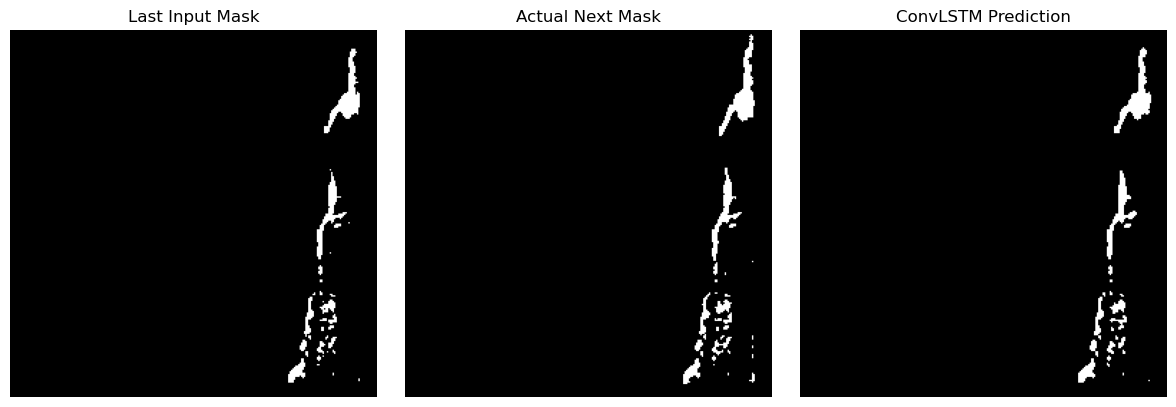

Actual foreground: 2.036 %
Predicted foreground: 1.881 %
Prediction contains only finite values: True


In [25]:

import torch
import numpy as np
import matplotlib.pyplot as plt

device = torch.device("cpu")
model.eval()

# Select one test sequence
idx = 0

sample = torch.as_tensor(
    X_test[idx:idx+1],
    dtype=torch.float32,
    device=device
)

actual_mask = np.asarray(y_test[idx, 0])

with torch.no_grad():
    logits = model(sample)
    probability = torch.sigmoid(logits)[0, 0].cpu().numpy()

# Convert probabilities into a binary mask
predicted_mask = (probability > 0.5).astype(np.uint8)

last_input_mask = X_test[idx, -1, 0] > 0.5

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(last_input_mask, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Last Input Mask")

axes[1].imshow(actual_mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Actual Next Mask")

axes[2].imshow(predicted_mask, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("ConvLSTM Prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Actual foreground:", round(100 * actual_mask.mean(), 3), "%")
print("Predicted foreground:", round(100 * predicted_mask.mean(), 3), "%")
print("Prediction contains only finite values:",
      np.isfinite(probability).all())


In [26]:

import numpy as np
import torch

model.eval()
threshold = 0.5

intersection = 0
union = 0
pred_pixels = 0
target_pixels = 0

base_intersection = 0
base_union = 0
base_pred_pixels = 0

area_errors = []
baseline_area_errors = []

with torch.no_grad():
    for start in range(0, len(X_test), 2):
        end = min(start + 2, len(X_test))

        xb = torch.as_tensor(
            X_test[start:end],
            dtype=torch.float32,
            device=device
        )

        targets = np.asarray(y_test[start:end, 0]) > 0.5

        probabilities = torch.sigmoid(model(xb))
        predictions = (
            probabilities[:, 0].cpu().numpy() > threshold
        )

        # Persistence baseline: reuse the last input mask
        baseline = X_test[start:end, -1, 0] > 0.5

        intersection += np.logical_and(
            predictions, targets
        ).sum()
        union += np.logical_or(predictions, targets).sum()
        pred_pixels += predictions.sum()
        target_pixels += targets.sum()

        base_intersection += np.logical_and(
            baseline, targets
        ).sum()
        base_union += np.logical_or(baseline, targets).sum()
        base_pred_pixels += baseline.sum()

        pred_area = predictions.mean(axis=(1, 2))
        target_area = targets.mean(axis=(1, 2))
        base_area = baseline.mean(axis=(1, 2))

        area_errors.extend(np.abs(pred_area - target_area))
        baseline_area_errors.extend(
            np.abs(base_area - target_area)
        )

conv_iou = intersection / union if union else 1.0
conv_dice = (
    2 * intersection / (pred_pixels + target_pixels)
    if pred_pixels + target_pixels else 1.0
)

base_iou = base_intersection / base_union if base_union else 1.0
base_dice = (
    2 * base_intersection / (base_pred_pixels + target_pixels)
    if base_pred_pixels + target_pixels else 1.0
)

print("TEST SET:", len(X_test), "sequences")
print("ConvLSTM IoU:", round(conv_iou, 4))
print("ConvLSTM Dice:", round(conv_dice, 4))
print("Persistence IoU:", round(base_iou, 4))
print("Persistence Dice:", round(base_dice, 4))
print("ConvLSTM area MAE (percentage points):",
      round(100 * np.mean(area_errors), 4))
print("Persistence area MAE (percentage points):",
      round(100 * np.mean(baseline_area_errors), 4))


TEST SET: 171 sequences
ConvLSTM IoU: 0.6772
ConvLSTM Dice: 0.8076
Persistence IoU: 0.7428
Persistence Dice: 0.8524
ConvLSTM area MAE (percentage points): 0.3388
Persistence area MAE (percentage points): 0.2736


In [27]:

import numpy as np

def inspect_temporal_change(X, y, name):
    last_masks = X[:, -1, 0] > 0.5
    targets = y[:, 0] > 0.5

    last_area = last_masks.mean(axis=(1, 2))
    target_area = targets.mean(axis=(1, 2))

    change_pixels = np.logical_xor(
        last_masks, targets
    ).mean(axis=(1, 2))

    print(f"\n{name}")
    print("Samples:", len(X))
    print(
        "Mean changed pixels (%):",
        round(100 * change_pixels.mean(), 4)
    )
    print(
        "Mean last-mask foreground (%):",
        round(100 * last_area.mean(), 4)
    )
    print(
        "Mean target foreground (%):",
        round(100 * target_area.mean(), 4)
    )
    print(
        "Samples with any mask change (%):",
        round(100 * np.mean(change_pixels > 0), 2)
    )

inspect_temporal_change(X_train, y_train, "TRAIN")
inspect_temporal_change(X_val, y_val, "VALIDATION")
inspect_temporal_change(X_test, y_test, "TEST")


NameError: name 'X_train' is not defined

In [28]:

for name in [
    "X_train", "y_train",
    "X_val", "y_val",
    "X_test", "y_test",
    "X_train_new", "y_train_new",
    "X_val_new", "y_val_new",
    "X_test_new", "y_test_new"
]:
    if name in globals():
        value = globals()[name]
        print(name, "exists | shape:", getattr(value, "shape", "unknown"))
    else:
        print(name, "NOT FOUND")


X_train NOT FOUND
y_train NOT FOUND
X_val NOT FOUND
y_val NOT FOUND
X_test exists | shape: (171, 5, 1, 256, 256)
y_test exists | shape: (171, 1, 256, 256)
X_train_new exists | shape: (291, 5, 1, 256, 256)
y_train_new exists | shape: (291, 1, 256, 256)
X_val_new exists | shape: (317, 5, 1, 256, 256)
y_val_new exists | shape: (317, 1, 256, 256)
X_test_new exists | shape: (171, 5, 1, 256, 256)
y_test_new exists | shape: (171, 1, 256, 256)


In [29]:

X_train, y_train = X_train_new, y_train_new
X_val, y_val = X_val_new, y_val_new
X_test, y_test = X_test_new, y_test_new

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)


Training: (291, 5, 1, 256, 256) (291, 1, 256, 256)
Validation: (317, 5, 1, 256, 256) (317, 1, 256, 256)
Testing: (171, 5, 1, 256, 256) (171, 1, 256, 256)


In [30]:

inspect_temporal_change(X_train, y_train, "TRAIN")
inspect_temporal_change(X_val, y_val, "VALIDATION")
inspect_temporal_change(X_test, y_test, "TEST")



TRAIN
Samples: 291
Mean changed pixels (%): 0.6185
Mean last-mask foreground (%): 2.3594
Mean target foreground (%): 2.3503
Samples with any mask change (%): 100.0

VALIDATION
Samples: 317
Mean changed pixels (%): 0.1819
Mean last-mask foreground (%): 0.7267
Mean target foreground (%): 0.711
Samples with any mask change (%): 99.68

TEST
Samples: 171
Mean changed pixels (%): 0.8
Mean last-mask foreground (%): 2.707
Mean target foreground (%): 2.7133
Samples with any mask change (%): 100.0


In [31]:

print("TRAINING GROUPS")
for p in train_paths:
    print(p)

print("\nVALIDATION GROUPS")
for p in val_paths:
    print(p)

print("\nTEST GROUPS")
for p in test_paths:
    print(p)


TRAINING GROUPS
D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0529_ref_geo.TIFF
D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0530_ref_geo.TIFF
D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0531_ref_geo.TIFF
D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0532_ref_geo.TIFF
D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0533_ref_geo.TIFF
D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0534_ref_geo.TIFF
D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0535_ref_geo.TIFF
D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0536_ref_geo.TIFF
D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0537_ref_geo.TIFF
D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0538_ref_geo.TIFF
D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius\IRX_0539_ref_geo

In [32]:

for name in [
    "group_items", "train_paths", "val_paths", "test_paths"
]:
    print(name, "available:", name in globals())


group_items available: True
train_paths available: True
val_paths available: True
test_paths available: True


In [33]:

def show_split_summary(name, paths):
    print(f"\n{name}: {len(paths)} frames")

    if not paths:
        print("No frames found.")
        return

    print("First frame:", paths[0].name)
    print("Last frame:", paths[-1].name)
    print("First folder:", paths[0].parent)
    print("Last folder:", paths[-1].parent)

show_split_summary("TRAIN", train_paths)
show_split_summary("VALIDATION", val_paths)
show_split_summary("TEST", test_paths)



TRAIN: 296 frames
First frame: IRX_0529_ref_geo.TIFF
Last frame: IRX_0824_ref_geo.TIFF
First folder: D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius
Last folder: D:\archive\Hanna Hammock\plot 1\duringburn\geo_thermal_tiff_celsius

VALIDATION: 322 frames
First frame: IRX_0826_ref_geo.TIFF
Last frame: IRX_1147_ref_geo.TIFF
First folder: D:\archive\Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part1
Last folder: D:\archive\Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part1

TEST: 176 frames
First frame: IRX_1171_ref_geo.TIFF
Last frame: IRX_1346_ref_geo.TIFF
First folder: D:\archive\Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part2
Last folder: D:\archive\Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part2


In [35]:

import re

def get_frame_number(path):
    match = re.search(r"IRX_(\d+)", path.name, re.IGNORECASE)
    return int(match.group(1)) if match else None

for name, paths in [
    ("TRAIN", train_paths),
    ("VALIDATION", val_paths),
    ("TEST", test_paths)
]:
    numbers = [get_frame_number(p) for p in paths]
    numbers = [n for n in numbers if n is not None]

    print(
        name,
        "| count:", len(numbers),
        "| min:", min(numbers) if numbers else None,
        "| max:", max(numbers) if numbers else None
    )


TRAIN | count: 296 | min: 529 | max: 824
VALIDATION | count: 322 | min: 826 | max: 1147
TEST | count: 176 | min: 1171 | max: 1346


In [36]:

import numpy as np

def compare_mask_changes(X, y, name):
    last_masks = X[:, -1, 0] > 0.5
    target_masks = y[:, 0] > 0.5

    changed_pixels = np.mean(
        last_masks != target_masks,
        axis=(1, 2)
    ) * 100

    last_area = last_masks.mean(axis=(1, 2)) * 100
    target_area = target_masks.mean(axis=(1, 2)) * 100

    print(f"\n{name}")
    print("Mean changed pixels (%):",
          round(float(changed_pixels.mean()), 4))
    print("Mean last-mask area (%):",
          round(float(last_area.mean()), 4))
    print("Mean target area (%):",
          round(float(target_area.mean()), 4))
    print("Samples with >0.1% changed pixels (%):",
          round(float(np.mean(changed_pixels > 0.1) * 100), 2))

compare_mask_changes(X_train_new, y_train_new, "TRAIN")
compare_mask_changes(X_val_new, y_val_new, "VALIDATION")
compare_mask_changes(X_test_new, y_test_new, "TEST")



TRAIN
Mean changed pixels (%): 0.6185
Mean last-mask area (%): 2.3594
Mean target area (%): 2.3503
Samples with >0.1% changed pixels (%): 100.0

VALIDATION
Mean changed pixels (%): 0.1819
Mean last-mask area (%): 0.7267
Mean target area (%): 0.711
Samples with >0.1% changed pixels (%): 40.38

TEST
Mean changed pixels (%): 0.8
Mean last-mask area (%): 2.707
Mean target area (%): 2.7133
Samples with >0.1% changed pixels (%): 100.0


In [39]:

import torch
import numpy as np
from torch.utils.data import DataLoader, TensorDataset

print("PyTorch:", torch.__version__)
print("DataLoader imported successfully")
print("Model available:", "model" in globals())
print("Device available:", "device" in globals())
print("Validation data available:", "X_val_new" in globals())


PyTorch: 2.14.1+cpu
DataLoader imported successfully
Model available: True
Device available: True
Validation data available: True


In [40]:
evaluate_model_and_persistence(
    X_val_new, y_val_new, "VALIDATION"
)


VALIDATION
ConvLSTM IoU: 0.7385
Persistence IoU: 0.7754
ConvLSTM area MAE (percentage points): 0.0982
Persistence area MAE (percentage points): 0.0766


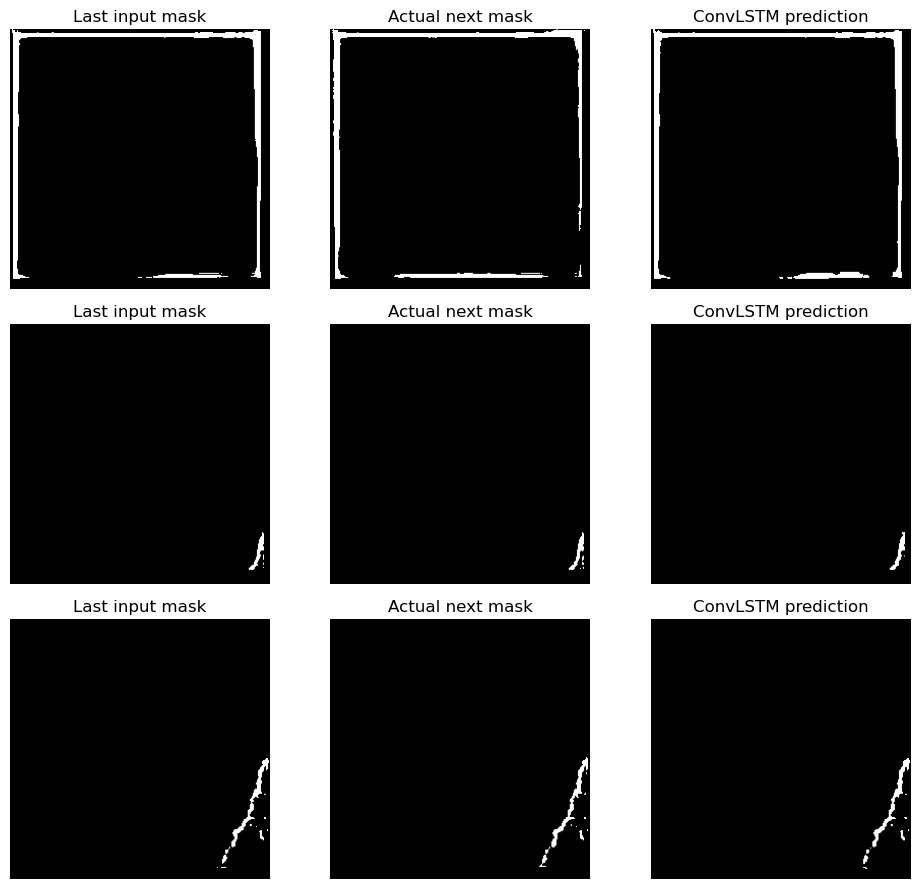

In [41]:

import matplotlib.pyplot as plt
import numpy as np
import torch

model.eval()
indices = [0, len(X_val_new) // 2, len(X_val_new) - 1]

fig, axes = plt.subplots(len(indices), 3, figsize=(10, 9))

with torch.no_grad():
    for row, idx in enumerate(indices):
        xb = torch.as_tensor(
            X_val_new[idx:idx+1],
            dtype=torch.float32,
            device=device
        )
        target = y_val_new[idx, 0] > 0.5
        last_mask = X_val_new[idx, -1, 0] > 0.5

        prediction = (
            torch.sigmoid(model(xb))[0, 0].cpu().numpy() > 0.5
        )

        axes[row, 0].imshow(last_mask, cmap="gray", vmin=0, vmax=1)
        axes[row, 0].set_title("Last input mask")

        axes[row, 1].imshow(target, cmap="gray", vmin=0, vmax=1)
        axes[row, 1].set_title("Actual next mask")

        axes[row, 2].imshow(prediction, cmap="gray", vmin=0, vmax=1)
        axes[row, 2].set_title("ConvLSTM prediction")

        for ax in axes[row]:
            ax.axis("off")

plt.tight_layout()
plt.show()


Sample 0: predicted changed pixels = 0.2518%, actual changed pixels = 3.0304%
Sample 158: predicted changed pixels = 0.0214%, actual changed pixels = 0.0229%
Sample 316: predicted changed pixels = 0.0320%, actual changed pixels = 0.0687%


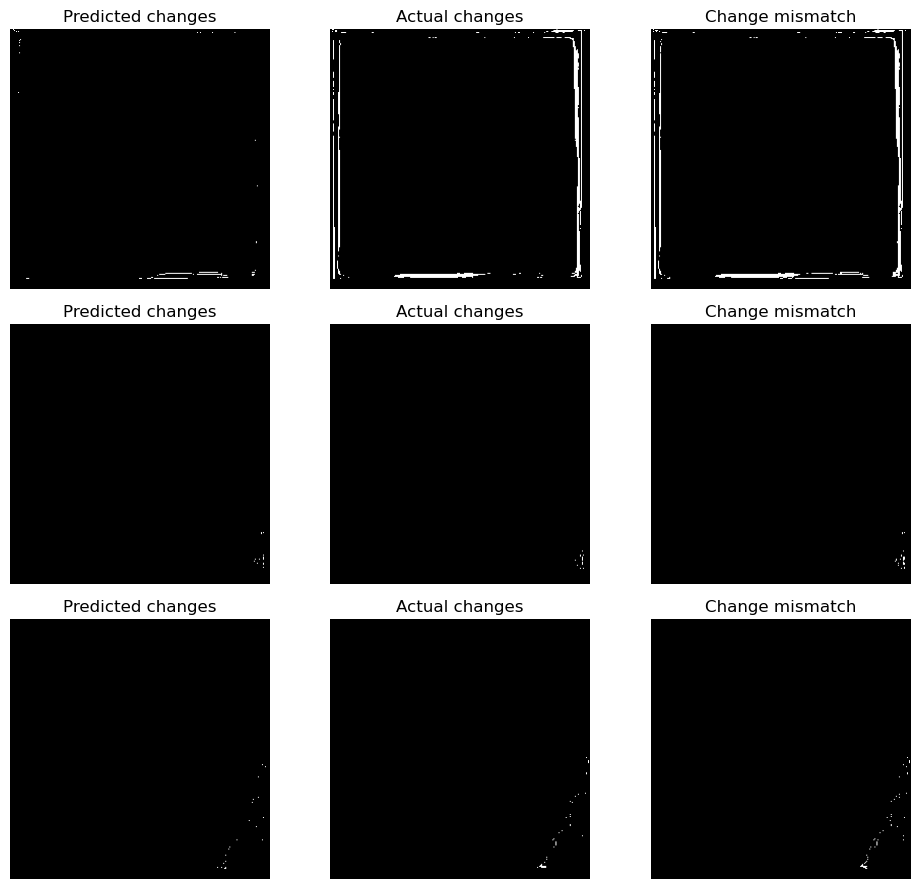

In [42]:

import numpy as np
import torch
import matplotlib.pyplot as plt

model.eval()
threshold = 0.5
indices = [0, len(X_val_new) // 2, len(X_val_new) - 1]

fig, axes = plt.subplots(len(indices), 3, figsize=(10, 9))

with torch.no_grad():
    for row, idx in enumerate(indices):
        xb = torch.as_tensor(
            X_val_new[idx:idx+1],
            dtype=torch.float32,
            device=device
        )

        last_mask = X_val_new[idx, -1, 0] > 0.5
        actual_mask = y_val_new[idx, 0] > 0.5

        predicted_mask = (
            torch.sigmoid(model(xb))[0, 0]
            .cpu().numpy() > threshold
        )

        changed_pred = np.logical_xor(last_mask, predicted_mask)
        changed_actual = np.logical_xor(last_mask, actual_mask)

        axes[row, 0].imshow(changed_pred, cmap="gray")
        axes[row, 0].set_title("Predicted changes")

        axes[row, 1].imshow(changed_actual, cmap="gray")
        axes[row, 1].set_title("Actual changes")

        axes[row, 2].imshow(
            np.logical_xor(changed_pred, changed_actual),
            cmap="gray"
        )
        axes[row, 2].set_title("Change mismatch")

        for ax in axes[row]:
            ax.axis("off")

        print(
            f"Sample {idx}: "
            f"predicted changed pixels = {100 * changed_pred.mean():.4f}%, "
            f"actual changed pixels = {100 * changed_actual.mean():.4f}%"
        )

plt.tight_layout()
plt.show()



Validation sample 0
Last input: {'total_foreground_pixels': 3786, 'border_foreground_pixels': 2237, 'interior_foreground_pixels': 1549, 'border_share_percent': np.float64(59.09)}
Next target: {'total_foreground_pixels': 3722, 'border_foreground_pixels': 2061, 'interior_foreground_pixels': 1661, 'border_share_percent': np.float64(55.37)}


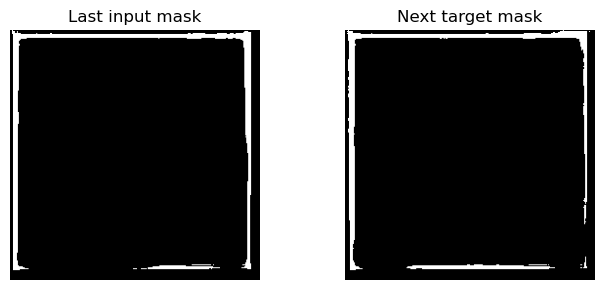


Validation sample 158
Last input: {'total_foreground_pixels': 164, 'border_foreground_pixels': 41, 'interior_foreground_pixels': 123, 'border_share_percent': np.float64(25.0)}
Next target: {'total_foreground_pixels': 169, 'border_foreground_pixels': 49, 'interior_foreground_pixels': 120, 'border_share_percent': np.float64(28.99)}


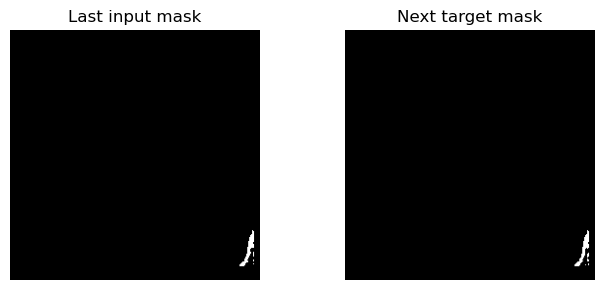


Validation sample 316
Last input: {'total_foreground_pixels': 495, 'border_foreground_pixels': 75, 'interior_foreground_pixels': 420, 'border_share_percent': np.float64(15.15)}
Next target: {'total_foreground_pixels': 508, 'border_foreground_pixels': 77, 'interior_foreground_pixels': 431, 'border_share_percent': np.float64(15.16)}


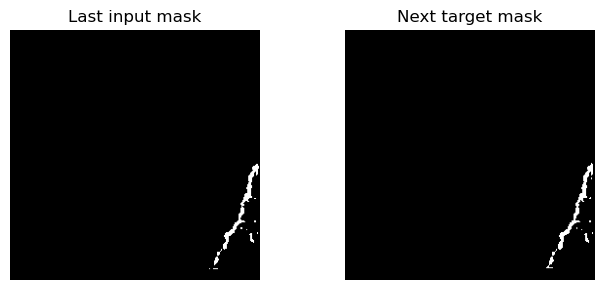

In [43]:

import numpy as np
import matplotlib.pyplot as plt

def inspect_mask_border(mask, border=8):
    mask = np.asarray(mask).squeeze() > 0.5

    edge = np.zeros_like(mask, dtype=bool)
    edge[:border, :] = True
    edge[-border:, :] = True
    edge[:, :border] = True
    edge[:, -border:] = True

    edge_pixels = np.logical_and(mask, edge).sum()
    interior_pixels = np.logical_and(mask, ~edge).sum()
    total_pixels = mask.sum()

    return {
        "total_foreground_pixels": int(total_pixels),
        "border_foreground_pixels": int(edge_pixels),
        "interior_foreground_pixels": int(interior_pixels),
        "border_share_percent": round(
            100 * edge_pixels / max(total_pixels, 1), 2
        )
    }

for idx in [0, len(X_val_new) // 2, len(X_val_new) - 1]:
    last_mask = X_val_new[idx, -1, 0]
    target_mask = y_val_new[idx, 0]

    print(f"\nValidation sample {idx}")
    print("Last input:", inspect_mask_border(last_mask))
    print("Next target:", inspect_mask_border(target_mask))

    fig, axes = plt.subplots(1, 2, figsize=(7, 3))
    axes[0].imshow(last_mask, cmap="gray", vmin=0, vmax=1)
    axes[0].set_title("Last input mask")
    axes[1].imshow(target_mask, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Next target mask")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()



Thermal: IRX_0826_ref_geo.TIFF
Mask exists: True


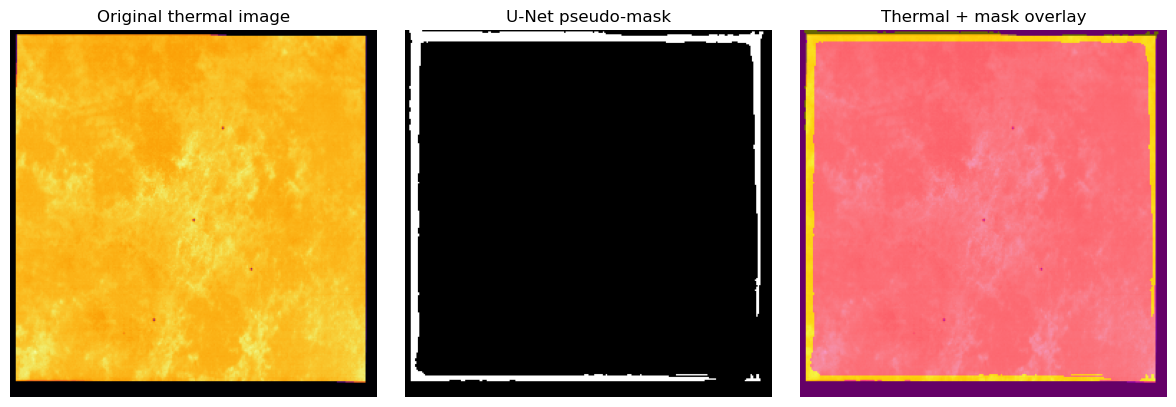


Thermal: IRX_0987_ref_geo.TIFF
Mask exists: True


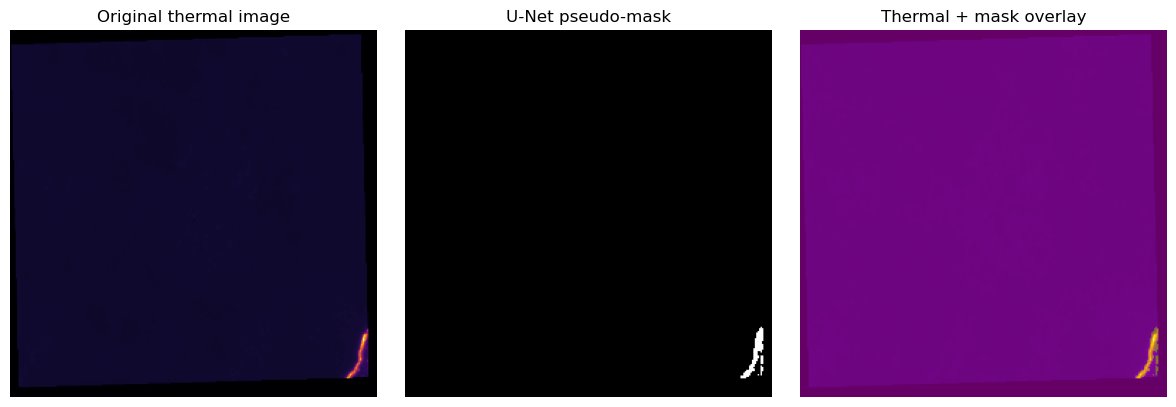


Thermal: IRX_1147_ref_geo.TIFF
Mask exists: True


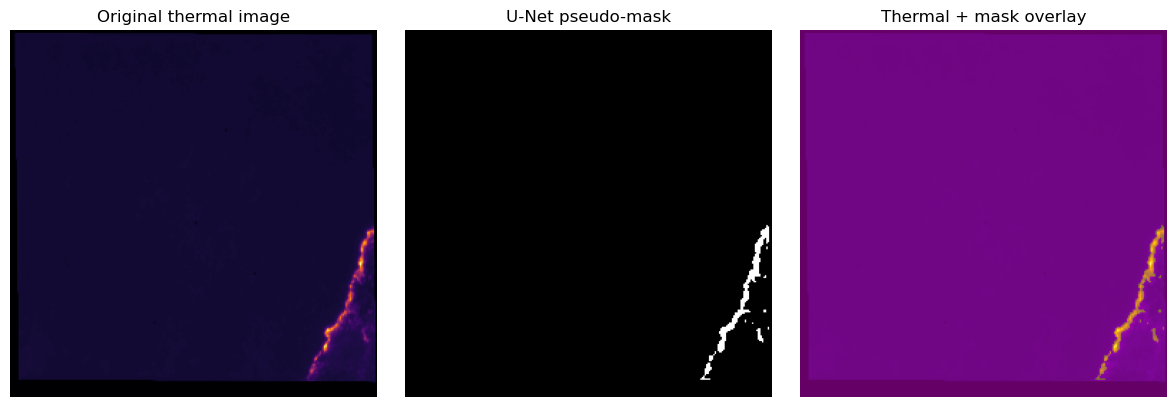

In [44]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import rasterio

# Use the first validation group
validation_folder, validation_paths = group_items[1]
validation_paths = sorted(
    validation_paths,
    key=lambda p: int(
        Path(p).stem.split("_")[1]
    )
)

MASK_ROOT = Path(r"D:\archive\unet_pseudo_masks")

def mask_path_for(source):
    relative = Path(source).relative_to(Path(r"D:\archive"))
    return MASK_ROOT / relative.parent / (
        Path(source).stem + "_mask.png"
    )

# Examine three frames from the validation group
for source in [
    validation_paths[0],
    validation_paths[len(validation_paths) // 2],
    validation_paths[-1],
]:
    source = Path(source)
    mask_path = mask_path_for(source)

    print("\nThermal:", source.name)
    print("Mask exists:", mask_path.exists())

    with rasterio.open(source) as src:
        thermal = src.read(1).astype(np.float32)

    if not mask_path.exists():
        print("Mask missing; skipping this frame.")
        continue

    import cv2
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

    if mask is None:
        print("Could not read mask.")
        continue

    thermal = np.nan_to_num(thermal)
    thermal = cv2.resize(
        thermal, (256, 256),
        interpolation=cv2.INTER_LINEAR
    )
    mask = cv2.resize(
        mask, (256, 256),
        interpolation=cv2.INTER_NEAREST
    ) > 127

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(thermal, cmap="inferno")
    axes[0].set_title("Original thermal image")
    axes[1].imshow(mask, cmap="gray")
    axes[1].set_title("U-Net pseudo-mask")
    axes[2].imshow(thermal, cmap="inferno")
    axes[2].imshow(mask, cmap="spring", alpha=0.4)
    axes[2].set_title("Thermal + mask overlay")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


In [45]:

from pathlib import Path
import cv2
import numpy as np

MASK_ROOT = Path(r"D:\archive\unet_pseudo_masks")
mask_paths = sorted(MASK_ROOT.rglob("*_mask.png"))

border = 8
results = []

for path in mask_paths:
    mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if mask is None:
        continue

    mask = mask > 127
    edge = np.zeros_like(mask, dtype=bool)
    edge[:border, :] = True
    edge[-border:, :] = True
    edge[:, :border] = True
    edge[:, -border:] = True

    total = int(mask.sum())
    edge_pixels = int((mask & edge).sum())
    foreground_pct = 100 * total / mask.size
    border_share_pct = 100 * edge_pixels / max(total, 1)

    results.append(
        (path, foreground_pct, border_share_pct, total)
    )

print("Masks inspected:", len(results))

print("\nMasks with high foreground coverage:")
for path, fg, edge_share, total in sorted(
    results, key=lambda r: r[1], reverse=True
)[:15]:
    print(
        f"{path.name} | foreground={fg:.2f}% "
        f"| border share={edge_share:.2f}% | pixels={total}"
    )

print("\nMasks with high border share:")
for path, fg, edge_share, total in sorted(
    results, key=lambda r: r[2], reverse=True
)[:15]:
    print(
        f"{path.name} | foreground={fg:.2f}% "
        f"| border share={edge_share:.2f}% | pixels={total}"
    )


Masks inspected: 794

Masks with high foreground coverage:
IRX_0832_ref_geo_mask.png | foreground=6.86% | border share=50.51% | pixels=4498
IRX_0827_ref_geo_mask.png | foreground=6.84% | border share=59.84% | pixels=4485
IRX_0826_ref_geo_mask.png | foreground=6.63% | border share=55.44% | pixels=4342
IRX_0833_ref_geo_mask.png | foreground=6.47% | border share=49.28% | pixels=4243
IRX_0720_ref_geo_mask.png | foreground=6.28% | border share=0.00% | pixels=4115
IRX_0836_ref_geo_mask.png | foreground=6.17% | border share=55.70% | pixels=4041
IRX_0828_ref_geo_mask.png | foreground=6.12% | border share=61.62% | pixels=4010
IRX_0837_ref_geo_mask.png | foreground=6.06% | border share=56.81% | pixels=3973
IRX_0835_ref_geo_mask.png | foreground=5.88% | border share=56.93% | pixels=3854
IRX_0834_ref_geo_mask.png | foreground=5.80% | border share=53.84% | pixels=3802
IRX_0830_ref_geo_mask.png | foreground=5.78% | border share=59.09% | pixels=3786
IRX_0717_ref_geo_mask.png | foreground=5.77% | bord

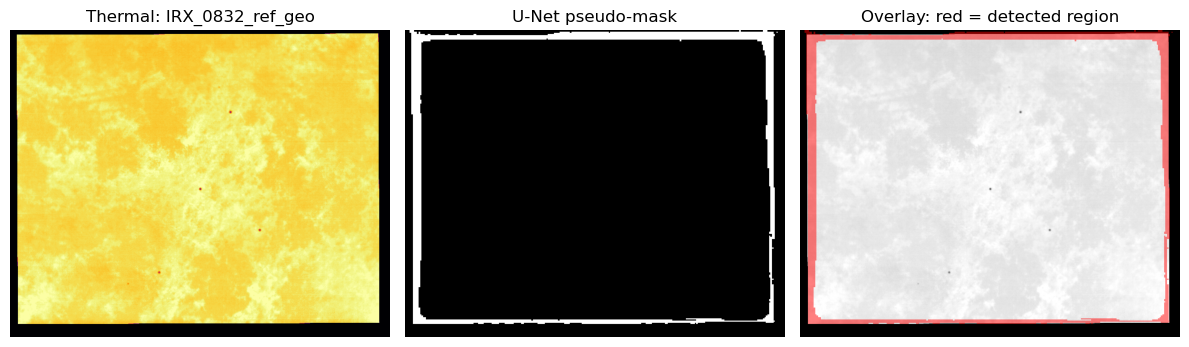

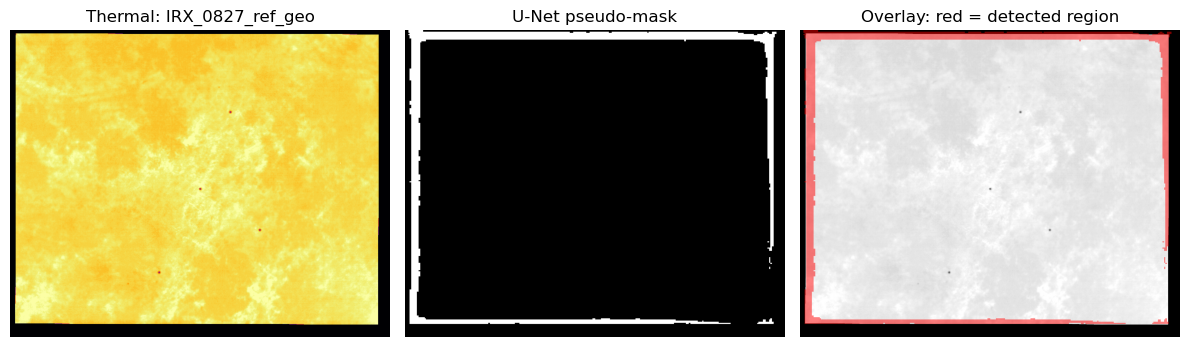

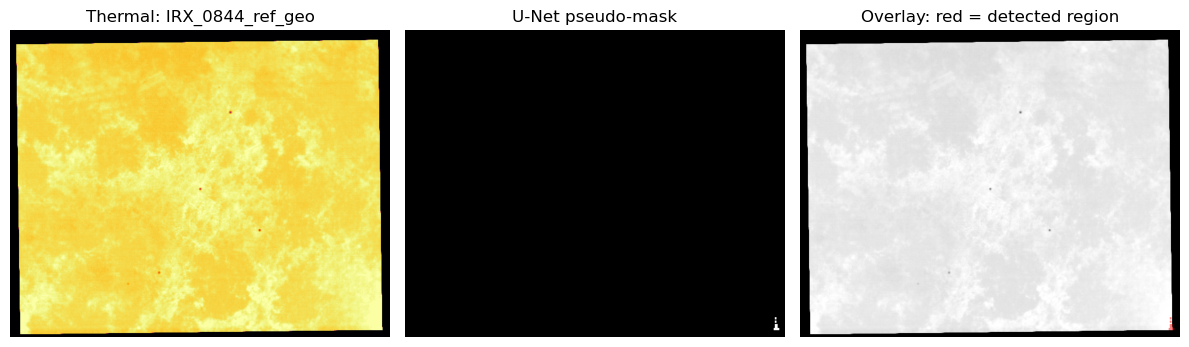

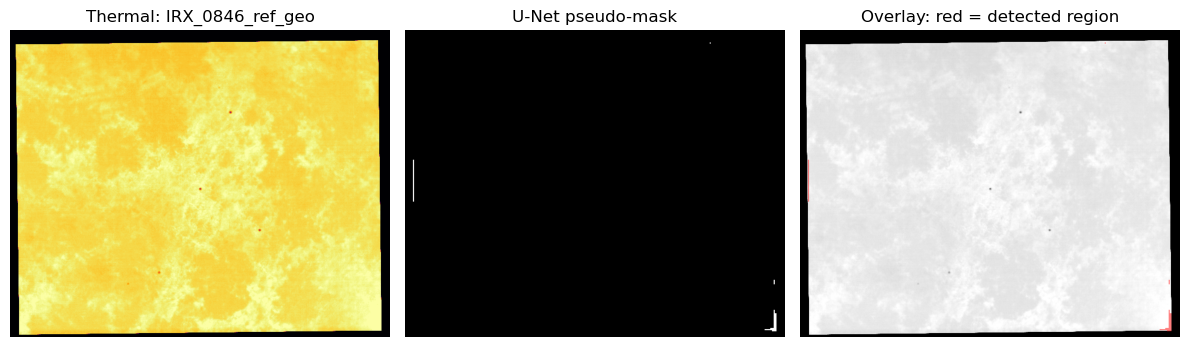

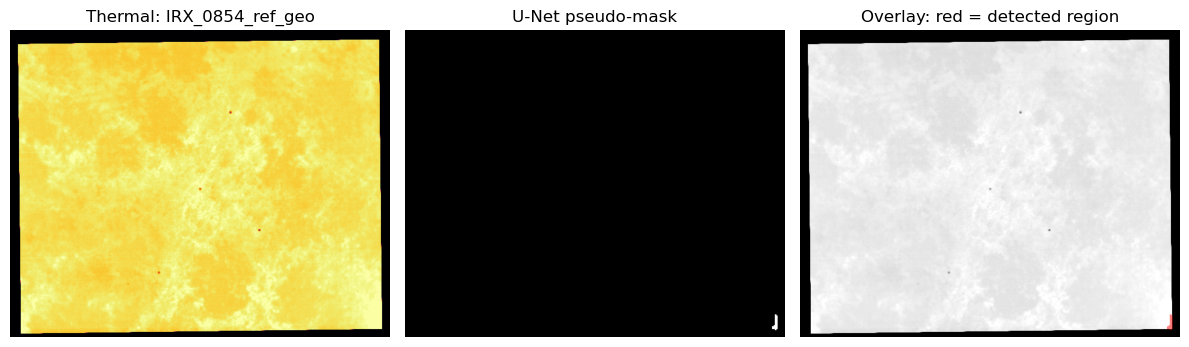

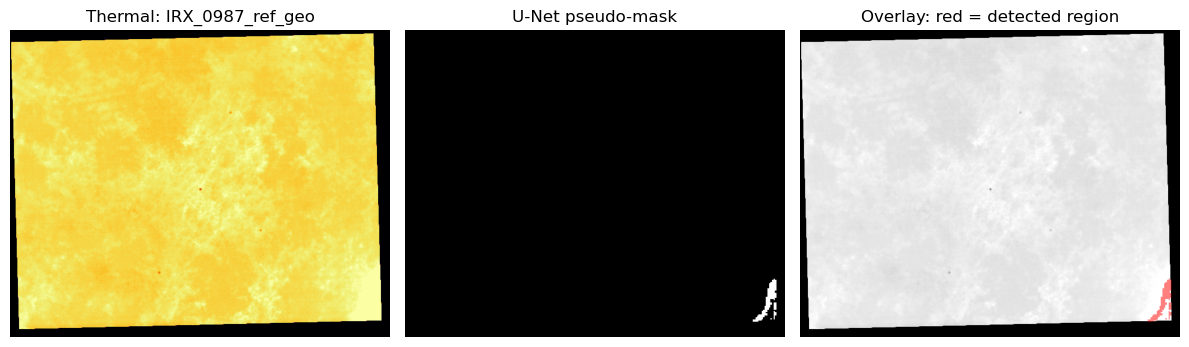

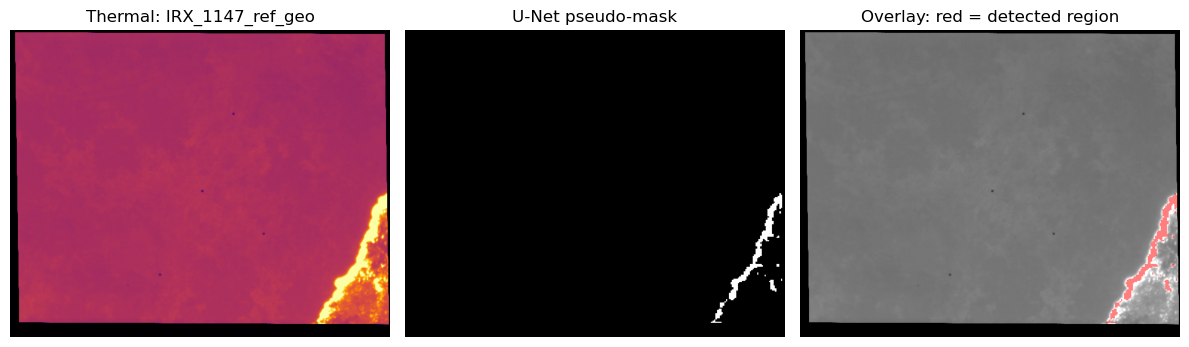

In [46]:

from pathlib import Path
import rasterio
import cv2
import numpy as np
import matplotlib.pyplot as plt

DATA_ROOT = Path(r"D:\archive\Hanna Hammock")
MASK_ROOT = Path(r"D:\archive\unet_pseudo_masks")

# Examples from your output: large masks and very sparse masks
sample_names = [
    "IRX_0832_ref_geo",
    "IRX_0827_ref_geo",
    "IRX_0844_ref_geo",
    "IRX_0846_ref_geo",
    "IRX_0854_ref_geo",
    "IRX_0987_ref_geo",
    "IRX_1147_ref_geo",
]

thermal_paths = list(DATA_ROOT.rglob("IRX_*_ref_geo.TIFF"))

for name in sample_names:
    thermal_matches = [
        p for p in thermal_paths if p.stem == name
    ]
    mask_matches = list(MASK_ROOT.rglob(name + "_mask.png"))

    if not thermal_matches or not mask_matches:
        print(f"Not found: {name}")
        continue

    thermal_path = thermal_matches[0]
    mask_path = mask_matches[0]

    with rasterio.open(thermal_path) as src:
        thermal = src.read(1).astype(np.float32)

    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

    if mask is None:
        print("Could not read mask:", mask_path)
        continue

    mask = cv2.resize(
        mask, (thermal.shape[1], thermal.shape[0]),
        interpolation=cv2.INTER_NEAREST
    ) > 127

    thermal_display = np.nan_to_num(thermal)
    lo, hi = np.percentile(thermal_display, [1, 99])
    thermal_display = np.clip(
        (thermal_display - lo) / max(hi - lo, 1e-6), 0, 1
    )

    overlay = np.stack(
        [thermal_display, thermal_display, thermal_display], axis=-1
    )
    overlay[mask] = (
        0.5 * overlay[mask] + 0.5 * np.array([1, 0, 0])
    )

    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    ax[0].imshow(thermal_display, cmap="inferno")
    ax[0].set_title(f"Thermal: {name}")
    ax[1].imshow(mask, cmap="gray")
    ax[1].set_title("U-Net pseudo-mask")
    ax[2].imshow(overlay)
    ax[2].set_title("Overlay: red = detected region")

    for a in ax:
        a.axis("off")

    plt.tight_layout()
    plt.show()


In [47]:

from pathlib import Path
import cv2
import numpy as np

MASK_ROOT = Path(r"D:\archive\unet_pseudo_masks")
mask_paths = list(MASK_ROOT.rglob("*.png"))

print("Total masks:", len(mask_paths))

results = []

for path in mask_paths:
    mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if mask is None:
        continue

    mask = mask > 127
    h, w = mask.shape

    # Define a 5-pixel border region
    border = np.zeros((h, w), dtype=bool)
    border[:5, :] = True
    border[-5:, :] = True
    border[:, :5] = True
    border[:, -5:] = True

    total_pixels = int(mask.sum())
    border_pixels = int((mask & border).sum())

    foreground_pct = 100 * total_pixels / mask.size
    border_share_pct = (
        100 * border_pixels / total_pixels
        if total_pixels else 0
    )

    results.append(
        (path.name, foreground_pct, border_share_pct, total_pixels)
    )

results.sort(key=lambda x: x[2], reverse=True)

print("\nTop 20 masks by border share:")
for name, foreground, border_share, pixels in results[:20]:
    print(
        f"{name} | foreground={foreground:.3f}% "
        f"| border share={border_share:.2f}% "
        f"| pixels={pixels}"
    )


Total masks: 794

Top 20 masks by border share:
IRX_1210_ref_geo_mask.png | foreground=0.433% | border share=51.76% | pixels=284
IRX_1204_ref_geo_mask.png | foreground=0.565% | border share=48.38% | pixels=370
IRX_1208_ref_geo_mask.png | foreground=0.526% | border share=47.54% | pixels=345
IRX_0893_ref_geo_mask.png | foreground=0.375% | border share=44.31% | pixels=246
IRX_0894_ref_geo_mask.png | foreground=0.352% | border share=43.72% | pixels=231
IRX_1209_ref_geo_mask.png | foreground=0.618% | border share=43.21% | pixels=405
IRX_1211_ref_geo_mask.png | foreground=0.508% | border share=41.14% | pixels=333
IRX_0892_ref_geo_mask.png | foreground=0.363% | border share=39.50% | pixels=238
IRX_1212_ref_geo_mask.png | foreground=0.470% | border share=39.29% | pixels=308
IRX_1202_ref_geo_mask.png | foreground=0.562% | border share=37.77% | pixels=368
IRX_1207_ref_geo_mask.png | foreground=0.670% | border share=37.59% | pixels=439
IRX_1213_ref_geo_mask.png | foreground=0.806% | border share=

Indexing TIFF images...
TIFF files indexed: 1621


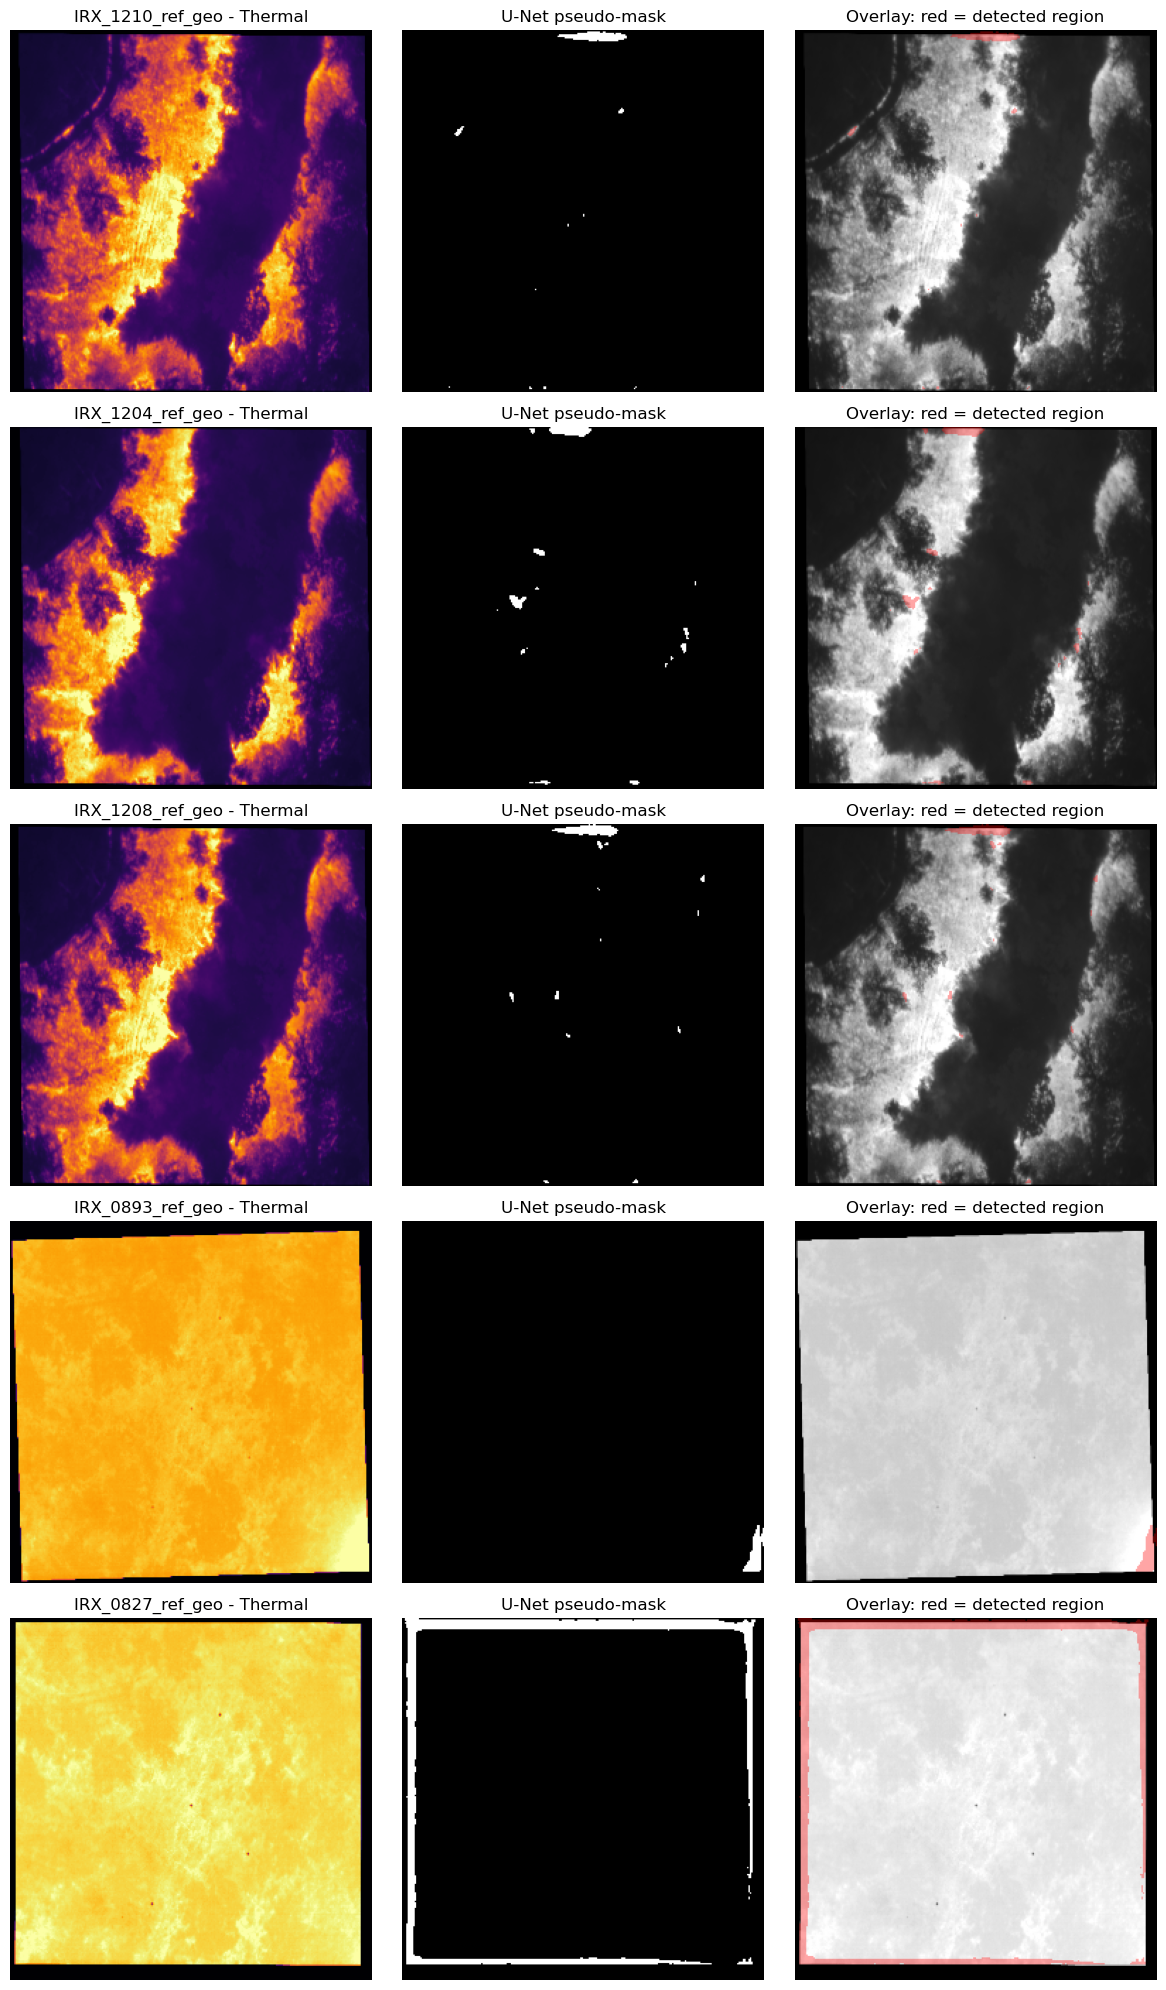

In [49]:

from pathlib import Path
import cv2
import numpy as np
import rasterio
import matplotlib.pyplot as plt

DATA_ROOT = Path(r"D:\archive\Hanna Hammock")
MASK_ROOT = Path(r"D:\archive\unet_pseudo_masks")

names = [
    "IRX_1210_ref_geo",
    "IRX_1204_ref_geo",
    "IRX_1208_ref_geo",
    "IRX_0893_ref_geo",
    "IRX_0827_ref_geo",
]

# Build an index of TIFF filenames and their real locations
print("Indexing TIFF images...")
tiff_index = {}

for path in DATA_ROOT.rglob("*"):
    if path.is_file() and path.suffix.lower() in (".tif", ".tiff"):
        tiff_index[path.stem.lower()] = path

print("TIFF files indexed:", len(tiff_index))

fig, axes = plt.subplots(len(names), 3, figsize=(12, 4 * len(names)))

for i, stem in enumerate(names):
    mask_matches = list(MASK_ROOT.rglob(stem + "_mask.png"))

    if not mask_matches:
        print("Mask not found:", stem)
        for ax in axes[i]:
            ax.axis("off")
        continue

    tif_path = tiff_index.get(stem.lower())

    if tif_path is None:
        print("TIFF not found:", stem)
        for ax in axes[i]:
            ax.axis("off")
        continue

    mask = cv2.imread(
        str(mask_matches[0]), cv2.IMREAD_GRAYSCALE
    ) > 127

    with rasterio.open(tif_path) as src:
        thermal = src.read(1).astype(np.float32)

    thermal = np.nan_to_num(thermal)
    lo, hi = np.percentile(thermal, [1, 99])

    if hi > lo:
        thermal = np.clip((thermal - lo) / (hi - lo), 0, 1)
    else:
        thermal = np.zeros_like(thermal)

    thermal = cv2.resize(
        thermal, (mask.shape[1], mask.shape[0]),
        interpolation=cv2.INTER_LINEAR
    )

    overlay = np.repeat(thermal[:, :, None], 3, axis=2)
    overlay[mask] = (
        0.65 * overlay[mask] + 0.35 * np.array([1, 0, 0])
    )

    axes[i, 0].imshow(thermal, cmap="inferno")
    axes[i, 0].set_title(stem + " - Thermal")

    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title("U-Net pseudo-mask")

    axes[i, 2].imshow(overlay)
    axes[i, 2].set_title("Overlay: red = detected region")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [51]:

from pathlib import Path
import numpy as np
import rasterio
import cv2

DATA_ROOT = Path(r"D:\archive\Hanna Hammock")
MASK_ROOT = Path(r"D:\archive\unet_pseudo_masks")

names = [
    "IRX_1210_ref_geo",
    "IRX_1204_ref_geo",
    "IRX_1208_ref_geo",
    "IRX_0893_ref_geo",
    "IRX_0827_ref_geo",
]

# Index thermal images by filename
tiff_index = {
    p.stem.lower(): p
    for p in DATA_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in (".tif", ".tiff")
}

for stem in names:
    tif_path = tiff_index.get(stem.lower())
    mask_matches = list(MASK_ROOT.rglob(stem + "_mask.png"))

    if tif_path is None or not mask_matches:
        print(stem, "- image or mask missing")
        continue

    with rasterio.open(tif_path) as src:
        thermal = src.read(1).astype(np.float32)

    mask = cv2.imread(
        str(mask_matches[0]), cv2.IMREAD_GRAYSCALE
    ) > 127

    thermal = np.nan_to_num(thermal, nan=np.nan)
    thermal = cv2.resize(
        thermal, (mask.shape[1], mask.shape[0]),
        interpolation=cv2.INTER_LINEAR
    )

    valid = np.isfinite(thermal)
    detected = mask & valid
    background = (~mask) & valid

    print(f"\n{stem}")
    print("Detected area (%):", round(100 * detected.sum() / valid.sum(), 3))

    if detected.any():
        print("Detected thermal median:", round(float(np.median(thermal[detected])), 4))
    else:
        print("Detected thermal median: no detected pixels")

    if background.any():
        print("Background thermal median:", round(float(np.median(thermal[background])), 4))
    else:
        print("Background thermal median: unavailable")



IRX_1210_ref_geo
Detected area (%): 0.433
Detected thermal median: 313.9736
Background thermal median: 93.9073

IRX_1204_ref_geo
Detected area (%): 0.565
Detected thermal median: 372.3141
Background thermal median: 67.1536

IRX_1208_ref_geo
Detected area (%): 0.526
Detected thermal median: 340.1338
Background thermal median: 86.452

IRX_0893_ref_geo
Detected area (%): 0.375
Detected thermal median: 380.2593
Background thermal median: 29.1477

IRX_0827_ref_geo
Detected area (%): 6.844
Detected thermal median: 29.0
Background thermal median: 29.1586


In [53]:

from pathlib import Path

root = Path(r"D:\archive")

print("Archive folder exists:", root.exists())

matches = list(root.rglob("unet_fire_segmentation_final.pth"))

print("Matching checkpoints found:", len(matches))

for p in matches:
    print(p)


Archive folder exists: True
Matching checkpoints found: 0


In [54]:

CHECKPOINT = Path(r"PASTE_THE_EXACT_PATH_PRINTED_ABOVE")

print("Checkpoint exists:", CHECKPOINT.exists())


Checkpoint exists: False


In [55]:

for p in Path(r"D:\archive").rglob("*.pth"):
    print(p)


D:\archive\convlstm_retrained_best.pth


In [61]:

from pathlib import Path

CHECKPOINT = Path(
    r"C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main\models\unet_fire_segmentation_final.pth"
)

print("Checkpoint exists:", CHECKPOINT.exists())
print("Checkpoint path:", CHECKPOINT)


Checkpoint exists: True
Checkpoint path: C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main\models\unet_fire_segmentation_final.pth


In [63]:

import torch

checkpoint = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("Top-level keys:", list(checkpoint.keys())[:20])

    if "state_dict" in checkpoint:
        saved_weights = checkpoint["state_dict"]
    elif "model_state_dict" in checkpoint:
        saved_weights = checkpoint["model_state_dict"]
    elif "state_dict" not in checkpoint and "model_state_dict" not in checkpoint and "model" in checkpoint and isinstance(checkpoint["model"], dict):
        saved_weights = checkpoint["model"]
    else:
        saved_weights = checkpoint

    print("\nFirst 20 saved parameter names:")
    for key in list(saved_weights.keys())[:20]:
        value = saved_weights[key]
        if hasattr(value, "shape"):
            print(key, tuple(value.shape))
        else:
            print(key, type(value).__name__)
else:
    print("Checkpoint is not a dictionary.")


Checkpoint type: dict
Top-level keys: ['model_state_dict', 'threshold', 'input_size', 'fire_dice', 'fire_iou', 'no_fire_clean_rate', 'task', 'output_classes']

First 20 saved parameter names:
encoder.conv1.weight (64, 3, 7, 7)
encoder.bn1.weight (64,)
encoder.bn1.bias (64,)
encoder.bn1.running_mean (64,)
encoder.bn1.running_var (64,)
encoder.bn1.num_batches_tracked ()
encoder.layer1.0.conv1.weight (64, 64, 3, 3)
encoder.layer1.0.bn1.weight (64,)
encoder.layer1.0.bn1.bias (64,)
encoder.layer1.0.bn1.running_mean (64,)
encoder.layer1.0.bn1.running_var (64,)
encoder.layer1.0.bn1.num_batches_tracked ()
encoder.layer1.0.conv2.weight (64, 64, 3, 3)
encoder.layer1.0.bn2.weight (64,)
encoder.layer1.0.bn2.bias (64,)
encoder.layer1.0.bn2.running_mean (64,)
encoder.layer1.0.bn2.running_var (64,)
encoder.layer1.0.bn2.num_batches_tracked ()
encoder.layer1.1.conv1.weight (64, 64, 3, 3)
encoder.layer1.1.bn1.weight (64,)


In [64]:

import torch
import segmentation_models_pytorch as smp
from pathlib import Path

CHECKPOINT = Path(
    r"C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main\models\unet_fire_segmentation_final.pth"
)

device = torch.device("cpu")

# Read the saved checkpoint
checkpoint = torch.load(
    CHECKPOINT,
    map_location=device,
    weights_only=True
)

# Extract the actual model weights
state = checkpoint["model_state_dict"]

print("Saved input size:", checkpoint.get("input_size"))
print("Saved threshold:", checkpoint.get("threshold"))
print("Saved output classes:", checkpoint.get("output_classes"))
print("Number of saved parameters:", len(state))

# Re-create the architecture used previously
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=1
).to(device)

# Load the weights
model.load_state_dict(state, strict=True)
model.eval()

print("U-Net loaded successfully!")
print("Device:", device)


Saved input size: (256, 256)
Saved threshold: 0.3
Saved output classes: 1
Number of saved parameters: 278
U-Net loaded successfully!
Device: cpu


Image exists: True


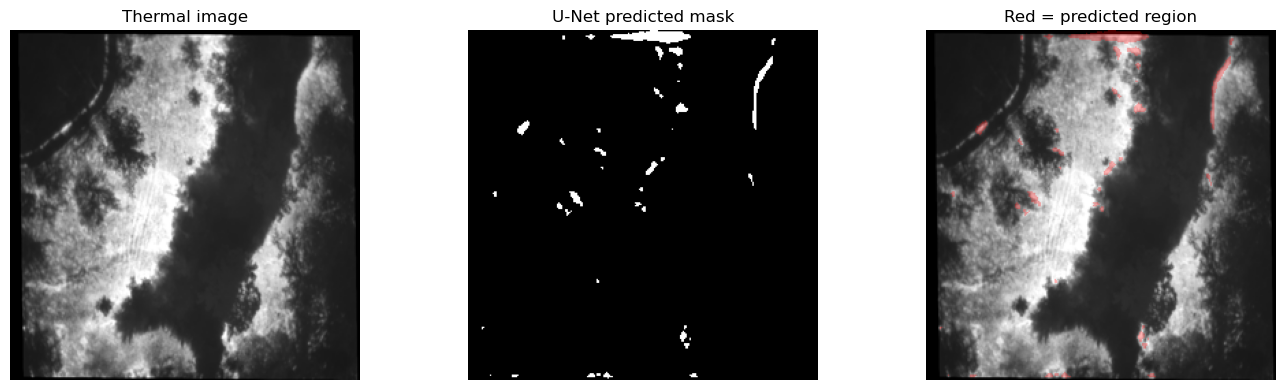

Threshold: 0.3
Predicted foreground: 1.663 %
Finite probabilities: True


In [65]:

import rasterio
import numpy as np
import matplotlib.pyplot as plt
import torch
from pathlib import Path

# Select one real thermal image from your test dataset
thermal_folder = Path(
    r"D:\archive\Hanna Hammock\plot 2\duringburn\geo_thermal_tiff_celsius\part2"
)

image_path = thermal_folder / "IRX_1210_ref_geo.TIFF"

print("Image exists:", image_path.exists())

if image_path.exists():
    with rasterio.open(image_path) as src:
        thermal = src.read(1).astype(np.float32)

    # Replace invalid values and normalize for visualization/model input
    thermal = np.nan_to_num(thermal, nan=0.0, posinf=0.0, neginf=0.0)
    low, high = np.percentile(thermal, [1, 99])

    if high <= low:
        raise ValueError("Thermal image has no usable intensity range.")

    normalized = np.clip((thermal - low) / (high - low), 0, 1)

    # U-Net expects 3 channels and 256x256 input
    from PIL import Image

    rgb = np.repeat(normalized[:, :, None], 3, axis=2)
    rgb_image = Image.fromarray((rgb * 255).astype(np.uint8))
    rgb_image = rgb_image.resize((256, 256))

    rgb_array = np.asarray(rgb_image).astype(np.float32) / 255.0
    tensor = torch.from_numpy(
        rgb_array.transpose(2, 0, 1)
    ).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        logits = model(tensor)
        probability = torch.sigmoid(logits)[0, 0].cpu().numpy()

    threshold = float(checkpoint.get("threshold", 0.3))
    predicted_mask = probability >= threshold

    overlay = rgb_array.copy()
    overlay[predicted_mask] = (
        0.7 * overlay[predicted_mask]
        + 0.3 * np.array([1.0, 0.0, 0.0])
    )

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    axes[0].imshow(rgb_array)
    axes[0].set_title("Thermal image")
    axes[1].imshow(predicted_mask, cmap="gray")
    axes[1].set_title("U-Net predicted mask")
    axes[2].imshow(overlay)
    axes[2].set_title("Red = predicted region")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    print("Threshold:", threshold)
    print("Predicted foreground:", round(100 * predicted_mask.mean(), 3), "%")
    print("Finite probabilities:", np.isfinite(probability).all())
else:
    print("Image not found. Check the folder path.")


In [66]:

print("U-Net checkpoint metadata")

for key in [
    "task",
    "input_size",
    "threshold",
    "output_classes",
    "fire_dice",
    "fire_iou",
    "no_fire_clean_rate",
]:
    print(f"{key}: {checkpoint.get(key, 'Not available')}")


U-Net checkpoint metadata
task: thermal_fire_segmentation
input_size: (256, 256)
threshold: 0.3
output_classes: 1
fire_dice: 0.8827
fire_iou: 0.794
no_fire_clean_rate: 94.74


In [67]:

from pathlib import Path

project = Path(
    r"C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main"
)

print("Project exists:", project.exists())

print("\nPossible training files:")
for p in project.rglob("*"):
    if p.is_file() and (
        p.suffix.lower() in {".ipynb", ".py"}
        and any(word in p.name.lower()
                for word in ["unet", "train", "segment", "fire"])
    ):
        print(p)


Project exists: True

Possible training files:
C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main\backend\services\unet_service.py
C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main\.venv\Lib\site-packages\rich\constrain.py
C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main\.venv\Lib\site-packages\rich\segment.py
C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main\.venv\Lib\site-packages\torch\distributions\constraints.py
C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main\.venv\Lib\site-packages\torch\distributions\constraint_registry.py
C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main\.venv\Lib\site-packages\torch\_export\passes\add_runtime_assertions_for_constraints_pass.py
C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main\.venv\Lib\site-packages\torch\_export\d

In [68]:

from pathlib import Path

service_file = Path(
    r"C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main\backend\services\unet_service.py"
)

print("File exists:", service_file.exists())

if service_file.exists():
    print(service_file.read_text(encoding="utf-8"))


File exists: True
import torch
import segmentation_models_pytorch as smp

class UNetService:
    def __init__(self, model_path: str):
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.UNET_PATH = model_path

    def load_model(self):
        self.unet = smp.Unet(
            encoder_name="resnet34",
            encoder_weights=None,
            in_channels=3,
            classes=1
        )
        
        checkpoint = torch.load(
            self.UNET_PATH,
            map_location=self.device
        )
        
        self.unet.load_state_dict(
            checkpoint["model_state_dict"]
        )
        
        self.threshold = checkpoint["threshold"]
        
        self.unet = self.unet.to(self.device)
        self.unet.eval()

    def predict(self, tensor):
        tensor = tensor.to(self.device)
        
        with torch.no_grad():
            pred = self.unet(tensor)
            pred = torch.sigmoid(pred)
            mask = (p

In [69]:

from pathlib import Path

project = Path(
    r"C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main"
)

for file in project.rglob("*.py"):
    if ".venv" in str(file):
        continue

    try:
        text = file.read_text(encoding="utf-8", errors="ignore")
    except OSError:
        continue

    if any(word in text.lower() for word in [
        "unet_service", "predict(", "cv2.resize",
        "normalize(", "transforms.to_tensor", "thermal"
    ]):
        print(f"\n--- {file.relative_to(project)} ---")
        for number, line in enumerate(text.splitlines(), 1):
            if any(word in line.lower() for word in [
                "unet_service", "cv2.resize", "normalize(",
                "to_tensor", "unsqueeze", "read(", "predict("
            ]):
                print(f"{number}: {line.strip()}")



--- backend\routers\prediction.py ---
9: from ..services.unet_service import UNetService
28: unet_service = UNetService("models/unet_fire_segmentation_final.pth")
29: unet_service.load_model()
38: unet_service=unet_service,
48: def predict(request: PredictionRequest, predictor: Predictor = Depends(get_predictor)):
70: prediction = predictor.predict(tiff_files)

--- backend\services\convlstm_service.py ---
131: def predict(self, fire_masks, thermal_images=None):
139: sequence = sequence.unsqueeze(1)
141: sequence = sequence.unsqueeze(0)

--- backend\services\predictor.py ---
9: from ..services.unet_service import UNetService
20: unet_service: UNetService,
24: self.unet_service = unet_service
28: def predict(self, sequence_paths: List[str]) -> PredictionResponse:
43: prob_map, mask = self.unet_service.predict(tensor)
48: prediction_np, future_mask = self.convlstm_service.predict(fire_masks, thermal_images)

--- backend\services\unet_service.py ---
31: def predict(self, tensor):

--- bac

In [70]:

from pathlib import Path

project = Path(
    r"C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main"
)

files = [
    project / "backend" / "utils" / "preprocessing.py",
    project / "backend" / "services" / "convlstm_service.py",
]

for file in files:
    print("\n" + "=" * 80)
    print("FILE:", file)
    print("EXISTS:", file.exists())
    print("=" * 80)

    if file.exists():
        print(file.read_text(encoding="utf-8", errors="replace"))



FILE: C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main\backend\utils\preprocessing.py
EXISTS: True
import cv2
import torch
import rasterio
import numpy as np

class ImagePreprocessor:
    def preprocess(self, path):
        with rasterio.open(path) as src:
            img = src.read(1)

        img = np.nan_to_num(img)

        img = (img - img.min()) / (img.max() - img.min() + 1e-8)

        img = (img * 255).astype(np.uint8)

        img = cv2.resize(img, (256,256))

        rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)

        tensor = torch.from_numpy(
            rgb.astype(np.float32)/255.0
        ).permute(2,0,1).unsqueeze(0)

        return img, tensor


FILE: C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main\backend\services\convlstm_service.py
EXISTS: True
import os
import matplotlib
matplotlib.use("Agg")
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

class ConvLSTMCell

In [71]:

from pathlib import Path
import torch

checkpoint_path = Path(
    r"D:\archive\convlstm_retrained_best.pth"
)

print("Checkpoint exists:", checkpoint_path.exists())

if checkpoint_path.exists():
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    print("Checkpoint type:", type(checkpoint).__name__)

    if isinstance(checkpoint, dict):
        print("Top-level keys:", list(checkpoint.keys())[:15])

        state = checkpoint.get("model_state_dict", checkpoint)

        if isinstance(state, dict):
            print("\nParameter names and shapes:")
            for name, value in list(state.items())[:10]:
                if torch.is_tensor(value):
                    print(name, tuple(value.shape))
                else:
                    print(name, type(value).__name__)


Checkpoint exists: True
Checkpoint type: OrderedDict
Top-level keys: ['cell.gates.weight', 'cell.gates.bias', 'output_layer.weight', 'output_layer.bias']

Parameter names and shapes:
cell.gates.weight (64, 17, 3, 3)
cell.gates.bias (64,)
output_layer.weight (1, 16, 1, 1)
output_layer.bias (1,)


In [72]:

import torch
import torch.nn as nn
from pathlib import Path

CHECKPOINT = Path(r"D:\archive\convlstm_retrained_best.pth")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class ConvLSTMCell(nn.Module):
    def __init__(self, input_channels=1, hidden_channels=16, kernel_size=3):
        super().__init__()
        self.hidden_channels = hidden_channels
        self.gates = nn.Conv2d(
            input_channels + hidden_channels,
            4 * hidden_channels,
            kernel_size,
            padding=kernel_size // 2
        )

    def forward(self, x, state):
        h, c = state
        i, f, o, g = torch.chunk(self.gates(torch.cat([x, h], dim=1)), 4, dim=1)
        i, f, o = torch.sigmoid(i), torch.sigmoid(f), torch.sigmoid(o)
        g = torch.tanh(g)
        c = f * c + i * g
        h = o * torch.tanh(c)
        return h, c

class ConvLSTMForecast(nn.Module):
    def __init__(self, hidden_channels=16):
        super().__init__()
        self.hidden_channels = hidden_channels
        self.cell = ConvLSTMCell(1, hidden_channels)
        self.output_layer = nn.Conv2d(hidden_channels, 1, kernel_size=1)

    def forward(self, x):
        batch, timesteps, channels, height, width = x.shape
        h = x.new_zeros(batch, self.hidden_channels, height, width)
        c = torch.zeros_like(h)

        for t in range(timesteps):
            h, c = self.cell(x[:, t], (h, c))

        return self.output_layer(h)

model = ConvLSTMForecast(hidden_channels=16).to(device)
state = torch.load(CHECKPOINT, map_location=device, weights_only=True)
model.load_state_dict(state, strict=True)
model.eval()

# Use the held-out test sequences created earlier.
X_test = X_test_new
sample = torch.as_tensor(X_test[:1], dtype=torch.float32, device=device)

with torch.no_grad():
    logits = model(sample)
    probabilities = torch.sigmoid(logits)
    predicted_mask = probabilities > 0.5

print("Checkpoint loaded:", True)
print("Device:", device)
print("Input shape:", tuple(sample.shape))
print("Output shape:", tuple(logits.shape))
print("Prediction finite:", torch.isfinite(probabilities).all().item())
print("Predicted foreground (%):",
      round(100 * predicted_mask.float().mean().item(), 4))


Checkpoint loaded: True
Device: cpu
Input shape: (1, 5, 1, 256, 256)
Output shape: (1, 1, 256, 256)
Prediction finite: True
Predicted foreground (%): 1.6907


In [73]:

import sys
import torch
from pathlib import Path

project = Path(
    r"C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main"
)

sys.path.insert(0, str(project / "backend"))

from services.convlstm_service import ConvLSTM

checkpoint_path = Path(r"D:\archive\convlstm_retrained_best.pth")

device = torch.device("cpu")
model = ConvLSTM().to(device)

state = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(state, strict=True)
model.eval()

sample = torch.as_tensor(
    X_test_new[:1],
    dtype=torch.float32,
    device=device
)

with torch.no_grad():
    logits = model(sample)
    probabilities = torch.sigmoid(logits)

print("Checkpoint loaded successfully")
print("Input shape:", tuple(sample.shape))
print("Output shape:", tuple(logits.shape))
print("Finite output:", torch.isfinite(probabilities).all().item())
print(
    "Predicted foreground (%):",
    round(100 * (probabilities > 0.5).float().mean().item(), 4)
)


Checkpoint loaded successfully
Input shape: (1, 5, 1, 256, 256)
Output shape: (1, 1, 256, 256)
Finite output: True
Predicted foreground (%): 1.6907


In [74]:

from pathlib import Path

project = Path(
    r"C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main"
)

for filename in ["prediction.py", "predictor.py", "convlstm_service.py"]:
    print(f"\n--- {filename} ---")

    matches = list(project.rglob(filename))

    for file in matches:
        if ".venv" in str(file):
            continue

        print("File:", file)

        try:
            lines = file.read_text(
                encoding="utf-8", errors="replace"
            ).splitlines()

            for i, line in enumerate(lines, 1):
                if any(word in line.lower() for word in [
                    "convlstmservice",
                    "convlstm_path",
                    "convlstm_retrained",
                    "load_model()",
                    "future_fire_prediction",
                ]):
                    print(f"{i}: {line.strip()}")
        except OSError as e:
            print("Read error:", e)



--- prediction.py ---
File: C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main\backend\routers\prediction.py
10: from ..services.convlstm_service import ConvLSTMService
29: unet_service.load_model()
31: convlstm_service = ConvLSTMService("models/future_fire_prediction.pth")
32: convlstm_service.load_model()

--- predictor.py ---
File: C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main\backend\services\predictor.py
10: from ..services.convlstm_service import ConvLSTMService
21: convlstm_service: ConvLSTMService,

--- convlstm_service.py ---
File: C:\Users\shash\OneDrive\Desktop\my projects\wildfire project\wildfire-project-main\backend\services\convlstm_service.py
54: class ConvLSTMService:
58: self.CONVLSTM_PATH = model_path
66: self.CONVLSTM_PATH,


In [75]:

from pathlib import Path

checkpoint = Path(r"D:\archive\convlstm_retrained_best.pth")

print("Checkpoint exists:", checkpoint.exists())
print("Checkpoint size (bytes):", checkpoint.stat().st_size if checkpoint.exists() else "Missing")


Checkpoint exists: True
Checkpoint size (bytes): 42301
